---
title: "Froment-Bischoff coke deactivation: the coke profile names the fouling mechanism"
description: "The 1961 paper that tied catalyst activity to deposited carbon instead of time on stream: all three of its solutions re-derived and met at observed second order by a pymrm transient bed, its four hand-era approximations measured one by one, a typo in eq. (49) adjudicated, and the descending-versus-ascending profile diagnostic mapped to where a real carbon assay could use it."
categories: [sec:B, struct:S4, struct:S5, tier:T0, data:tier6, phase:gas, phase:gas-solid]
date: 2026-08-06
---

# Froment-Bischoff coke deactivation: the coke profile names the fouling mechanism

**Catalog ID:** `B2.2` · **Structures:** `S4` (1D transient PDE),
`S5` (convection-dominated, van Leer TVD) · **Tier:** T0

Before 1961, coked catalysts were bookkept against the clock: activity was
correlated with time on stream, following Voorhies' $c = m\,t'^n$. Froment and
Bischoff's move, stated in their abstract as the point of the paper, was to
make activity a function of **the carbon actually sitting on the catalyst**,
and to couple the carbon's own formation kinetics to the reactor's continuity
equation. Two mechanisms are worked out: coke from a reaction **parallel** to
the main one (fed by the reactant) and coke from a reaction **consecutive** to
it (fed by the product). The result that made the paper canonical: the coke
lays down as a **profile** along the bed, descending for a parallel
mechanism and ascending for a consecutive one, so the shape of the deposit is a
fingerprint of its chemistry, and the locus of maximum rate (and of maximum
heat release) **travels down the bed** as the catalyst ages.

The paper is from the hand-computation era ("a numerical treatment on an
electronic computer ... did not seem justified at the present state of
knowledge"), so everything in it is closed forms, series windows and
asymptotic patches. That makes it unusually checkable: this page re-derives
every printed solution independently, meets all three with one pymrm
finite-volume bed, **measures each of the paper's four approximations** (the
$\gamma = 0$ closure, the series window, the large-$\eta$ patch, and the
$\eta \simeq t$ change of variables), settles a typo in eq. (49) from the
paper's own preceding line, and then asks the question the profile diagnostic
exists to answer: **how good does a carbon assay have to be before the profile
can actually name the mechanism?**

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.10"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B2.2-froment-bischoff-coking"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import simpson
from scipy.optimize import minimize_scalar
from pymrm import compute_boundary_values, minmod
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, cite_data, load_data, load_meta
from model import (Bed, SolveFailed, cbar_slope, ce_exact, ce_patch, contrast_of_profile,  # this page's model.py
                   err_vs_exact, half_contrast, pe_exact, pe_gamma_ode, ph_exact)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
COL = {"PE": "#0072B2", "PH": "#E69F00", "CE": "#009E73"}   # Okabe-Ito, the same on every figure
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught

## Background

**The source, precisely.** G. F. Froment and K. B. Bischoff, "Non-steady state
behaviour of fixed bed catalytic reactors due to catalyst fouling", *Chemical
Engineering Science* **16**(3-4) 189-201 (1961), doi:10.1016/0009-2509(61)80030-4,
Laboratorium voor Organische Technische Chemie, Rijksuniversiteit Gent,
identified from the scan's own running head, by-line and abstract (the OCR
renders the year as "1901" and the by-line as "FI~OMENT"; the volume, page
range and received-date are unambiguous). The scan is CCITT-G4 bilevel at
300 ppi native; every numeral on this page was read from cropped
native-resolution renders, never from the text layer.

**The catalogue cites two papers.** Its "CES 16 (1961), 17 (1962)" second half
is Part II, *Kinetic data in reactors with catalyst decay*, CES **17** (1962)
105. **Part II was not read for this page**: no scan of it exists on disk, only
an Elsevier api-text whose OCR class is known to drop decimal points, and the
data rules forbid building on that. This page is built from Part I alone, which
carries the model the case is named for in full.

**Where it sits in the literature.** The paper opens against the empirical
tradition it replaces: Voorhies' 1945 correlation of average coke with time
(*Ind. Eng. Chem.* **37** 318, the subject of `B2.1`, quoted here only as this
paper quotes it), Rudershausen & Watson, Tyuryaev et al., and Wilson & den
Herder. Its central objection is mechanistic: coke "must result in some way
either from the reactant or from the product", so its rate belongs in the same
continuity framework as the main reaction, and once there is a profile, an
activity correlated *only* with time is ill-posed, because activity then varies
along the bed. Section 7(a) closes the loop by showing the coupled models
reproduce the *range* of the observed Voorhies exponents; this page recomputes
that comparison exactly and finds it discriminates more than the authors
claimed. The deactivation ladder continues in `B2.3` (Levenspiel's separable
rate forms) and `B2.4` (Beeckman-Froment pore blockage); the same authors'
fixed-bed canon (`C2.10`/`D3.4` o-xylene, `B1.3` generalised modulus) shares
the conventions used here.

## The published model

All equation numbers are the paper's; every equation below was transcribed from
a cropped 300 dpi render and is verified symbolically or numerically further
down the page.

**Continuity, and the exact change of variables.** With a flat velocity
profile, no diffusion of any sort, constant density and mole number, and
isothermal operation, the reactant mole fraction $y$ and the carbon content of
the catalyst $c$ (kg carbon / kg catalyst) obey (eqs. 1-7)

$$
\frac{\partial y}{\partial t} + \frac{\partial y}{\partial z}
  = -\frac{\Omega \rho_B d_p}{F}\, r_A, \qquad
\frac{\partial c}{\partial t} = \frac{\epsilon \rho_A \Omega d_p}{F}\, r_c ,
$$

in reduced time $t = F t' / (\epsilon \rho_A \Omega d_p)$ and reduced length
$z = z'/d_p$. The pair is hyperbolic, and the substitution $\eta = t - z$,
time measured from the passage of the displacement front, removes the
$\partial y/\partial t$ term **exactly** (eqs. 6-7). The paper then notes that
for practical purposes $t \gg z$, so $\eta \simeq t$; this page *measures* what
that reading costs.

**Mechanisms** (eqs. 8-11), both first order in $A$:

- **parallel**: $A \to R$ (rate $k_1 P y$) and $A \to C$ (rate $k_2 P y$),
  coke fed by the *reactant*;
- **consecutive**: $A \to R \to C$ with $r_A = k_1 P y$ and
  $r_c = k_2 P (1-y)$, coke fed by the *product*.

**Deactivation** (eqs. 12-13): $k_i = k_i^\circ \phi_i$, with the activity a
function of the *local carbon content* (the paper's thesis) in one of two
printed forms: exponential $\phi = e^{-\alpha c}$ (empirical) or hyperbolic
$\phi = 1/(1+Kc)$ (a Langmuir picture: $K$ "a sort of adsorption equilibrium
constant" between deposited carbon and fouled sites; a footnote generalises to
$1/(\beta + Kc)$ and sets it aside).

**The three solved cases**, in the canonical variables used throughout this
page ($x \equiv az$, and $T \equiv \alpha b \eta$ for the exponential cases,
$T \equiv K b \eta$ for the hyperbolic one, with
$a = \Omega \rho_B d_p P k_1^\circ / F$,
$b = \Omega \rho_A \epsilon d_p P k_2^\circ / F$,
$\gamma = k_2^\circ/k_1^\circ$; boundary and initial data $y(0,\eta)=1$, pure
feed, and $c(z,0)=0$, fresh bed):

| case | gas phase | coke | exact solution |
|---|---|---|---|
| **PE** parallel, exponential (18)-(19), only $k_1$ affected | $y_x = -(e^{-C}+\gamma)\,y$ | $C_T = y$ | for $\gamma=0$, eqs. (32)-(33): $y = \{1 + e^{-T}(e^{x}-1)\}^{-1}$, $e^{-C} = \{1 + e^{-x}(e^{T}-1)\}^{-1}$ |
| **PH** parallel, hyperbolic (34)-(35), both $k$'s affected, $a$ built on $k_1^\circ + k_2^\circ$ | $y_x = -\dfrac{y}{1+W}$ | $W_T = \dfrac{y}{1+W}$ | eqs. (36)-(37): $s = \sqrt{1+2T}-1$, $W e^{W} = s\,e^{s-x}$, $y = e^{-x+s-W}$ |
| **CE** consecutive, exponential (40)-(41), only $k_1$ affected | $y_x = -e^{-C}\,y$ | $C_T = 1-y$ | no closed form; the paper gives a 4-term series (44) and a large-$\eta$ patch (46)+(49) |

with $C \equiv \alpha c$ and $W \equiv K c$. Three things worth noticing, each
verified below:

- **The PE pair is symmetric**: $e^{-C}(x,T)$ is $y(T,x)$ with the arguments
  swapped: deactivation at depth $x$ mirrors breakthrough at time $T$.
- **The PH implicit pair collapses to $y = W/s$** (substitute (37) into (36)),
  which makes its verification elementary and is nowhere stated in the paper.
- **The paper's own duality** (printed as a substitution table in Section 6):
  the consecutive system is the parallel system with
  $y \leftrightarrow e^{-\alpha c}$, $z \leftrightarrow \eta$ and
  $\gamma \to -1$.

**Derived quantities.** The paper's intermediate eq. (29),
$C_x + \gamma C = e^{-C} - 1$ with $C(0) = T$, is an *exact* ODE reduction in
$x$ that holds for **any** $\gamma$; this page uses it as an independent
solution route. The dimensionless main-reaction rate is $r' = y\,e^{-\alpha c}$
(53), whose surface over $(z,\eta)$ is the paper's Fig. 5; and the
distance-averaged carbon $c_{z\,\mathrm{av.}}$ (51)-(52) is what an in-situ
regeneration experiment measures, the paper's bridge to the Voorhies
exponents.

**A printed slip in eq. (49), settled below.** Eq. (48) reads
$\int_1^y e^{-\alpha b \eta y'}/y' \, dy' = -\,a z\, e^{-\alpha b \eta}$
(italic $a$: the dimensionless group). The very next line, eq. (49), prints
$ei(\alpha b \eta y) = ei(\alpha b \eta) + \boldsymbol{\alpha} z\,
e^{-\alpha b \eta}$, with $\alpha$ where the substitution
$ei(u) = \int_u^\infty e^{-\lambda}/\lambda\, d\lambda$ requires $a$. For the
paper's own Appendix-2 constants $\alpha/a$ is a factor of order $10^2$, so
the two readings differ grossly; the adjudication cell below measures both.
(Two cosmetic misprints are recorded in the data sidecar rather than here:
$\rho_F$ vs $\rho_A$ for the same density, and a $\mathrm{kg/m^2}$ unit on
$\rho_B$ in the notation table.)

## Parameters and assumptions

**Everything runs at the paper's own operating point.** Appendix 2 fixes the
practical ranges from the authors' (unpublished) ethylbenzene-dehydrogenation
data: $P = 1$ atm, $\epsilon = 0.38$, $\rho_B = 1130\ \mathrm{kg/m^3}$,
$\rho_F = 1.33\ \mathrm{kg/m^3}$, $F = 0.30$ kg/hr, $L' = 0.084$ m,
$\Omega = 6.3\times10^{-4}\ \mathrm{m^2}$, $T = 600\,^\circ$C, with
$k_1^\circ \simeq 10\ \mathrm{atm^{-1}hr^{-1}}$ from a preliminary analysis
and order-of-magnitude estimates
$k_2^\circ \simeq 0.01\ \mathrm{atm^{-1}hr^{-1}}$, $\alpha \simeq 100$,
$K \simeq 200$. From these the paper prints three worked intermediates,
$aL = 0.2\,k_1^\circ \simeq 2.0$ (A.1), $\alpha b t = 5$ (A.2a),
$K b t = 10$ (A.2b), which are recomputed below and anchor the transcription.
So the production ranges of this page are the paper's: $az \in [0,2]$,
$\alpha b \eta \in [0,5]$ (to 10 for the consecutive case, 20 for the
hyperbolic, matching Figs. 2-3), and $\gamma = k_2^\circ/k_1^\circ = 10^{-3}$.

Note $d_p$ appears in $a$, $b$ and $t$ separately but cancels from $az$,
$\alpha b\eta$ and $aL$, which is why the paper never has to state it, and why
this page can run entirely from printed values.

**Assumptions inherited from the paper** (all stated by it): isothermal
operation; plug flow, no axial diffusion; constant density and mole number;
both reactions first order in their gas-phase reactant; deactivation through
$\phi(c)$ multiplying the fresh-bed coefficient; in PE and CE only the main
reaction deactivates ($\phi_2 = 1$), in PH both deactivate identically. The
$(z,\eta)$ change of variables is exact; the only approximations anywhere are
the four the paper makes to *solve* the system ($\gamma = 0$ in PE, the
series window and the large-$\eta$ patch in CE, and $\eta \simeq t$ when
comparing with clock-time experiments), and each of the four is measured on
this page.

**Fit/test label: nothing on this page is fitted.** The model has no free
parameter anywhere: every computation is fixed by the printed dimensionless
groups. The paper's $k_2^\circ$, $\alpha$, $K$ are the *authors'*
order-of-magnitude estimates against their own data, used here (as in the
paper) only to fix the ranges above; no measurement exists in the paper to
validate against, so every agreement below is a **reproduction or an
internal-consistency check, never a validation**. The meta.yaml, README and
data sidecars carry the same label.

In [3]:
# Appendix 2: every printed intermediate recomputed from the printed inputs.
COND = load_data("froment-bischoff-1961-appendix2-conditions.csv", page=PAGE).set_index("name")
PRINTED = load_data("froment-bischoff-1961-printed-claims.csv", page=PAGE).set_index("claim_id")
V = COND["value"]


def appendix2(v):
    """The paper's worked intermediates and the time-scale separation from inputs ``v``."""
    pre = v.Omega * v.rho_B * v.P * v.L_prime / v.F                # printed 0.2
    return {"appendix2_aL_prefactor": pre,
            "appendix2_aL": pre * v.k1_0,                          # printed 2.0 (A.1)
            "appendix2_alpha_b_t": v.alpha * v.P * v.k2_0 * v.t_process,   # printed 5 (A.2a)
            "appendix2_K_b_t": v.K * v.P * v.k2_0 * v.t_process,           # printed 10 (A.2b)
            "appendix2_gamma": v.k2_0 / v.k1_0,
            # eps_s = alpha b/a: units of coking time T per unit of gas transit x
            "appendix2_eps_s": v.alpha * (v.rho_F * v.eps_void * v.k2_0) / (v.rho_B * v.k1_0),
            "t_res_hr": v.rho_F * v.eps_void * v.Omega * v.L_prime / v.F}


A2 = appendix2(V)
for k in ("appendix2_aL_prefactor", "appendix2_aL", "appendix2_alpha_b_t", "appendix2_K_b_t",
          "appendix2_gamma", "appendix2_eps_s"):
    claims.value(k, A2[k], rtol=1e-9, note="arithmetic on printed inputs")
GAMMA_PAPER, EPS_PAPER = A2["appendix2_gamma"], A2["appendix2_eps_s"]

for col, factor in (("Omega", 10.0), ("k2_0", 10.0)):
    v_bad = V.copy()
    v_bad[col] *= factor
    bad = appendix2(v_bad)
    for k in ("appendix2_aL_prefactor", "appendix2_aL", "appendix2_alpha_b_t", "appendix2_K_b_t",
              "appendix2_gamma", "appendix2_eps_s"):
        if bad[k] != A2[k]:
            brk(f"{col} transcribed {factor:g} times too large ({V[col]:g} -> {v_bad[col]:g})", k, bad[k])

display(Markdown(f"""
| printed intermediate | paper prints | recomputed from the printed inputs |
|---|---|---|
| $aL$ prefactor $\\Omega\\rho_B P L'/F$ | {COND.loc['aL_prefactor', 'value']:g} | {A2['appendix2_aL_prefactor']:.4f} |
| $aL$ (eq. A.1) | {COND.loc['aL', 'value']:.1f} | {A2['appendix2_aL']:.3f} |
| $\\alpha b t$ (eq. A.2a) | {COND.loc['alpha_b_t', 'value']:g} | {A2['appendix2_alpha_b_t']:.2f} |
| $Kbt$ (eq. A.2b) | {COND.loc['K_b_t', 'value']:g} | {A2['appendix2_K_b_t']:.2f} |

The prefactor deviates from the printed {COND.loc['aL_prefactor', 'value']:g} by
{100 * abs(A2['appendix2_aL_prefactor'] / COND.loc['aL_prefactor', 'value'] - 1):.2f} %, the
paper's own rounding, propagated into its {COND.loc['aL', 'value']:.1f}. (A.2a) and (A.2b) are
exact products of printed values; they confirm the transcription of five constants at once but
cannot fail by less than a whole misprint, so they are anchors rather than sensitive checks.
Two derived numbers used throughout: $\\gamma = k_2^\\circ/k_1^\\circ = {GAMMA_PAPER:g}$, a factor
{PRINTED.loc['gamma_threshold', 'printed_value'] / GAMMA_PAPER:.0f} below the paper's own
{PRINTED.loc['gamma_threshold', 'printed_value']:g} validity bound for its $\\gamma=0$ closure,
and the time-scale separation: gas residence time {3600 * A2['t_res_hr']:.2f} s against a
{V.t_process:g} hr run, i.e. $\\eta$ and $t$ differ by {A2['t_res_hr'] / V.t_process:.1e} of the
run, slope $\\varepsilon_s = \\alpha b/a = {EPS_PAPER:.2e}$ in canonical units. That is the whole
content of the paper's "$\\eta \\simeq t$"; it is measured as an error below.
"""))


| printed intermediate | paper prints | recomputed from the printed inputs |
|---|---|---|
| $aL$ prefactor $\Omega\rho_B P L'/F$ | 0.2 | 0.1993 |
| $aL$ (eq. A.1) | 2.0 | 1.993 |
| $\alpha b t$ (eq. A.2a) | 5 | 5.00 |
| $Kbt$ (eq. A.2b) | 10 | 10.00 |

The prefactor deviates from the printed 0.2 by
0.33 %, the
paper's own rounding, propagated into its 2.0. (A.2a) and (A.2b) are
exact products of printed values; they confirm the transcription of five constants at once but
cannot fail by less than a whole misprint, so they are anchors rather than sensitive checks.
Two derived numbers used throughout: $\gamma = k_2^\circ/k_1^\circ = 0.001$, a factor
20 below the paper's own
0.02 validity bound for its $\gamma=0$ closure,
and the time-scale separation: gas residence time 0.32 s against a
5 hr run, i.e. $\eta$ and $t$ differ by 1.8e-05 of the
run, slope $\varepsilon_s = \alpha b/a = 4.47e-05$ in canonical units. That is the whole
content of the paper's "$\eta \simeq t$"; it is measured as an error below.


## The data

**The paper contains no measurements.** Its figures are the authors' own
computed curves; its experimental content is limited to the Appendix-2
operating conditions and the Voorhies-type exponents it quotes from four other
papers. Data tier is therefore **6** and the two datasets of this page are
transcriptions, not measurements:

| dataset | what it holds |
|---|---|
| `appendix2-conditions` | the printed operating conditions, estimated constants, and the paper's three worked intermediates (pp. 200-201) |
| `printed-claims` | every quantitative prose claim: the five quoted Voorhies exponents, the $\gamma \le 0.02$ / 5 % statement, the series and asymptotic validity windows, the three Fig.-4 slope readings (pp. 193-198) |

Both sidecars carry the same fit/test label as this page: nothing is a held-out
measurement, and nothing on the page is fitted to either file.

**No figure was digitised, deliberately.** Figs. 1(a)-3(b) plot the printed
closed forms and approximations at parameter values stated in the text or
readable from curve labels; Fig. 4 plots averages of those same solutions;
Fig. 5 is the rate surface of eq. (54). Everything figure-shaped on this page
is **recomputed from the printed equations** and can be compared with the paper
by eye. The one figure-adjacent finding runs the other way: the text says
Fig. 3(b)'s large-$\eta$ curves were computed from eqs. (46)+(49), and this
page measures that those equations sit systematically low, so the *printed
figure* inherits a quantified bias (below).

**Cross-page obligations:** no other page's dataset is loaded. The Voorhies
numbers quoted here are transcribed from *this* paper's Section 7(a) only;
`B2.1` (Voorhies 1945) owns the original. Part II (CES 17, 1962) was not read
from an image and contributes nothing here.

In [4]:
print(cite_data(load_meta("froment-bischoff-1961-appendix2-conditions.csv", page=PAGE)))
print(cite_data(load_meta("froment-bischoff-1961-printed-claims.csv", page=PAGE)))

Froment, G. F.; Bischoff, K. B. (1961) — Chemical Engineering Science 16(3-4) 189-201 — doi:10.1016/0009-2509(61)80030-4 — table
Froment, G. F.; Bischoff, K. B. (1961) — Chemical Engineering Science 16(3-4) 189-201 — doi:10.1016/0009-2509(61)80030-4 — table


## PyMRM implementation

One class, `Bed` in `model.py`, serves all three cases, the full-$\gamma$
system and the mixed parallel+consecutive generalisation. The gas phase is
quasi-steady in $x$ at each coking time $T$ (exactly the paper's $(z,\eta)$
system; the full transient with the $\varepsilon_s\,\partial y/\partial T$ term
retained is solved separately below and measured against it):

- **Operators assembled once**: `ConvFluxTVD` (van Leer, velocity 1) gives the
  face fluxes *and their exact Jacobian*; `construct_div` with `nu=0`
  (Cartesian) on an `(n, 1)` layout, fields on the last axis. The activity
  enters as `construct_coefficient_matrix(g)`, rebuilt each solve because $g$
  depends on the coke.
- **Boundary conditions on the outward normal**: the inlet is Dirichlet,
  $y = 1$, written `{"a": 0, "b": 1, "d": 1}`. The outlet is a pure outflow,
  `{"outflow": True}`, whose face carries the last *cell* value. That value
  sits half a cell upstream of the face, an $O(h)$ error wherever $y$ has a
  gradient at the outlet, and here it has one ($y' = -g y$). The bed therefore
  adds one constant matrix, assembled once, that moves the outlet face value to
  the linear extrapolation of the last two cells (the last row of
  `interp_cntr_to_stagg` without a bc). The table below measures what each
  outlet choice does to the order.
- **Each gas profile by `newton`** (`damping="monotone"`, `stagnation=True`,
  step tolerance $10^{-12}$ on $y \sim 1$), raising when it reports no success.
  At frozen $C$ the problem is linear in $y$ except for the limiter, so the
  Newton solve resolves only the limiter's nonlinearity.
- **A second route to the same discrete equations**: van Leer deferred
  correction (the upwind operator implicit, the limiter correction from the
  previous sweep), swept until the largest change is below $10^{-13}$. Its
  convergence and its agreement with `newton` are measured below.
- **Coking marched by Heun's method** in $T$, two gas solves per step, records
  only on the step grid. Both refinement axes ($n$ in $x$, $m$ in $T$) are
  swept independently and jointly below, with error measured against exact
  solutions through the passage of the activity ridge.

First, the references must agree with *each other* before they judge the bed.

In [5]:
# The references cross-checked: the closed forms (32)-(33) against the paper's
# eq. (29) integrated as an ODE in x (no shared algebra), and spot identities.
T_CHK = np.linspace(0.5, 5.0, 10)
X_EVAL = np.linspace(0.0, 2.0, 401)
Y29, C29 = pe_gamma_ode(T_CHK, 0.0, X_EVAL)
y_cf, C_cf = pe_exact(X_EVAL[None, :], T_CHK[:, None])
claims.bound("pe_closedform_vs_eq29_ode", max(np.abs(Y29 - y_cf).max(), np.abs(C29 - C_cf).max()),
             max=1e-10, basis="tolerance", note="DOP853 at rtol 1e-12, atol 1e-14")
brk("eq. (29) route run at gamma = 0.02 instead of 0", "pe_closedform_vs_eq29_ode",
    max(np.abs(pe_gamma_ode(T_CHK, 0.02, X_EVAL)[0] - y_cf).max(), 0.0))
swap = abs(pe_exact(1.3, 0.4)[0] - np.exp(-pe_exact(0.4, 1.3)[1]))
claims.bound("pe_swap_symmetry", swap, max=1e-14, basis="identity", structural=True,
             note="exp(-C)(x, T) = y(T, x) from the closed forms")
ph_inlet = abs(ph_exact(0.0, 4.0)[1] - (np.sqrt(9.0) - 1.0))
claims.bound("ph_inlet_W_equals_s", ph_inlet, max=1e-12, basis="identity", structural=True,
             note="W(0, T) = s(T) from W e^W = s e^s")
ce_anchor = float(np.abs(ce_exact([0.0], np.linspace(0.5, 40.0, 20))[1]).max())
claims.bound("ce_inlet_anchor", ce_anchor, max=1e-14, basis="identity", structural=True,
             note="C(0, T) = 0: pure feed, no product, no consecutive coke at the inlet")
_ce_tight = ce_exact(X_EVAL[::10], [1.0, 5.0, 10.0], rtol=1e-13, atol=1e-15)
_ce_base = ce_exact(X_EVAL[::10], [1.0, 5.0, 10.0])
claims.bound("ce_reference_tolerance", max(np.abs(_ce_tight[0] - _ce_base[0]).max(),
                                           np.abs(_ce_tight[1] - _ce_base[1]).max()),
             max=1e-10, basis="tolerance", note="DOP853 rtol 1e-12 against 1e-13")
brk("consecutive-case reference integrated at rtol 1e-6", "ce_reference_tolerance",
    np.abs(ce_exact(X_EVAL[::10], [1.0, 5.0, 10.0], rtol=1e-6, atol=1e-8)[1] - _ce_tight[1]).max())
print(f"closed forms (32)-(33) against the eq. (29) ODE route (gamma = 0): below 1e-10 "
      f"(here {claims['pe_closedform_vs_eq29_ode']:.0e})")
print(f"swap symmetry exp(-C)(x, T) = y(T, x): below 1e-14 (here {swap:.0e}); "
      f"PH inlet W(0, T) = s(T): below 1e-12 (here {ph_inlet:.0e})")
print(f"consecutive reference: C(0, T) = 0 at the inlet (here {ce_anchor:.0e}); "
      f"rtol 1e-12 against 1e-13 changes it by below 1e-10 (here {claims['ce_reference_tolerance']:.0e})")

closed forms (32)-(33) against the eq. (29) ODE route (gamma = 0): below 1e-10 (here 1e-11)
swap symmetry exp(-C)(x, T) = y(T, x): below 1e-14 (here 0e+00); PH inlet W(0, T) = s(T): below 1e-12 (here 0e+00)
consecutive reference: C(0, T) = 0 at the inlet (here 0e+00); rtol 1e-12 against 1e-13 changes it by below 1e-10 (here 2e-13)


In [6]:
# Symbolic verification of every transcribed solution and series. Each residual is
# identically zero once the transcription is right: structural checks of the
# transcription and of this page's algebra, blind to any numerical error.
x_, T_, g_ = sp.symbols("x T gamma", positive=True)

# (32)-(33) satisfy the PE system with gamma = 0
y_s = 1 / (1 + sp.exp(-T_) * (sp.exp(x_) - 1))
C_s = sp.log(1 + sp.exp(-x_) * (sp.exp(T_) - 1))
res_pe = (sp.simplify(sp.diff(y_s, x_) + sp.exp(-C_s) * y_s), sp.simplify(sp.diff(C_s, T_) - y_s))

# (36)-(37) satisfy the PH system, through the parametrisation x(W, T)
W_ = sp.symbols("W", positive=True)
s_of_T = sp.sqrt(1 + 2 * T_) - 1
x_of_WT = s_of_T - W_ + sp.log(s_of_T / W_)     # from W e^W = s e^(s - x)
y_of_WT = W_ / s_of_T                           # (36) with (37) substituted
dxdW, dxdT = sp.diff(x_of_WT, W_), sp.diff(x_of_WT, T_)
res_ph = (sp.simplify(sp.diff(y_of_WT, W_) / dxdW + y_of_WT / (1 + W_)),
          sp.simplify(-dxdT / dxdW - y_of_WT / (1 + W_)))


def picard(f, ic, var, order):
    """Taylor solution of dU/dvar = f(U), U(0) = ic, by Picard iteration."""
    U = ic
    for k in range(1, order + 1):
        U = sp.expand(ic + sp.integrate(sp.series(f(U), var, 0, k).removeO(), var))
    return U


# (30): C_x = e^-C - 1 - gamma C, C(0) = T; the printed x and x^2 coefficients
C30 = picard(lambda c: sp.exp(-c) - 1 - g_ * c, T_, x_, 2)
ok30 = (sp.simplify(C30.coeff(x_, 1) - (-g_ * T_ + sp.exp(-T_) - 1)) == 0,
        sp.simplify(C30.coeff(x_, 2) - sp.Rational(1, 2) * (-g_ - sp.exp(-T_))
                    * (-g_ * T_ + sp.exp(-T_) - 1)) == 0)
# (44): Chat = -ln y obeys dChat/dT = 1 - Chat - e^-Chat, Chat(0) = x
LNY = sp.expand(-picard(lambda c: 1 - c - sp.exp(-c), x_, T_, 4))
ok44 = (sp.simplify(LNY.coeff(T_, 1) - (x_ + sp.exp(-x_) - 1)) == 0,
        sp.simplify(LNY.coeff(T_, 2) - sp.Rational(1, 2) * (sp.exp(-x_) - 1)
                    * (x_ + sp.exp(-x_) - 1)) == 0)
ce_series = sp.lambdify((x_, T_), LNY, "numpy")          # ln y, four terms beyond -x
ce_series_2 = sp.lambdify((x_, T_), sp.expand(-picard(lambda c: 1 - c - sp.exp(-c), x_, T_, 2)), "numpy")
SYMBOLIC_OK = all(r == 0 for r in res_pe + res_ph) and all(ok30) and all(ok44)
claims.exact("symbolic_transcription_checks", bool(SYMBOLIC_OK), structural=True,
             note="(32)-(33), (36)-(37) residuals zero; series (30) and (44) coefficients match")
print("PE (32)-(33) residuals in (18)-(19) at gamma = 0:", res_pe)
print("PH (36)-(37) residuals in (34)-(35):", res_ph)
print("series (30): printed x and x^2 coefficients reproduced:", ok30)
print("series (44): printed eta and eta^2 coefficients reproduced:", ok44)

PE (32)-(33) residuals in (18)-(19) at gamma = 0: (0, 0)
PH (36)-(37) residuals in (34)-(35): (0, 0)
series (30): printed x and x^2 coefficients reproduced: (True, True)
series (44): printed eta and eta^2 coefficients reproduced: (True, True)


In [7]:
# Fresh bed (C = 0, exact y = exp(-x)): spatial accuracy, and the outlet face.
NF = (100, 200, 400, 800)
VARIANTS = (("first-order upwind", dict(limiter=None, outlet="outflow")),
            ("van Leer, outlet face = last cell ({'outflow': True})", dict(outlet="outflow")),
            ("van Leer, outlet zero gradient ({'a': 1, 'b': 0, 'd': 0})", dict(outlet="zero_gradient")),
            ("van Leer, outlet face linearly extrapolated", dict()))
FRESH = {}
for label, kw in VARIANTS:
    errs = []
    for n in NF:
        bed = Bed("PE", n=n, **kw)
        errs.append(np.abs(bed.solve_y(np.zeros(n)) - np.exp(-bed.x_c)).max())
    FRESH[label] = (errs, [np.log2(errs[i] / errs[i + 1]) for i in range(len(NF) - 1)])
LAB_X = VARIANTS[-1][0]
claims.value("fresh_bed_maxerr_n200", FRESH[LAB_X][0][1])
claims.bound("fresh_bed_order_min", min(FRESH[LAB_X][1]), min=1.9, max=2.1, basis="theory",
             note="second-order face values everywhere, the outlet face included")
for label, _ in VARIANTS[:-1]:
    brk(label, "fresh_bed_maxerr_n200", FRESH[label][0][1])
    brk(label, "fresh_bed_order_min", min(FRESH[label][1]))

bed = Bed("PE", n=200)
y_fresh = bed.solve_y(np.zeros(200))
EXACT_OUT = np.exp(-2.0)
OUT_ZG = float(np.ravel(compute_boundary_values(y_fresh.reshape(-1, 1), bed.x_f, bed.x_c,
                                                (bed.bc[0], {"a": 1.0, "b": 0.0, "d": 0.0}))[2])[0])
claims.value("outlet_read_err_extrapolated_face", abs(bed.outlet_value(y_fresh) - EXACT_OUT))
claims.value("outlet_read_err_boundary_values", abs(OUT_ZG - EXACT_OUT))
claims.value("outlet_read_err_last_cell", abs(y_fresh[-1] - EXACT_OUT))
_b_out = Bed("PE", n=200, outlet="outflow")
_y_out = _b_out.solve_y(np.zeros(200))
brk("outlet read from Bed(outlet='outflow'): compute_boundary_values gives the last cell",
    "outlet_read_err_extrapolated_face", abs(_b_out.outlet_value(_y_out) - EXACT_OUT))
_b100 = Bed("PE", n=100)
_y100 = _b100.solve_y(np.zeros(100))
brk("100 cells instead of 200", "outlet_read_err_last_cell", abs(_y100[-1] - EXACT_OUT))
brk("100 cells instead of 200", "outlet_read_err_boundary_values",
    abs(float(np.ravel(compute_boundary_values(_y100.reshape(-1, 1), _b100.x_f, _b100.x_c,
                                               (_b100.bc[0], {"a": 1.0, "b": 0.0, "d": 0.0}))[2])[0])
        - EXACT_OUT))

rows = "\n".join(f"| {lab} | {e[1]:.1e} | {', '.join(f'{o:.2f}' for o in o_)} |"
                 for lab, (e, o_) in FRESH.items())
display(Markdown(f"""
Fresh-bed spatial accuracy (exact $y = e^{{-x}}$), max-norm at $n = 200$ and the
observed orders over $n = {NF[0]}, {NF[1]}, {NF[2]}, {NF[3]}$:

| scheme | max error ($n = 200$) | observed orders |
|---|---|---|
{rows}

Both outlet dictionaries leave the scheme first order: the outlet cell carries an $O(h)$
error, whether its face takes the cell value or the zero-gradient reconstruction. With the
outlet face extrapolated, the scheme is second order. **Reading the outlet** (exact
$y(L) = e^{{-2}}$, $n = 200$): the last cell centre is off by
{claims['outlet_read_err_last_cell']:.1e}, `compute_boundary_values` under the zero-gradient
dict by {claims['outlet_read_err_boundary_values']:.1e} (it evaluates the bc it is given, and
that bc is the biased ingredient), and the face the bed transports, the linear extrapolation,
by {claims['outlet_read_err_extrapolated_face']:.1e}. All outlet numbers on this page are that
face value.
"""))


Fresh-bed spatial accuracy (exact $y = e^{-x}$), max-norm at $n = 200$ and the
observed orders over $n = 100, 200, 400, 800$:

| scheme | max error ($n = 200$) | observed orders |
|---|---|---|
| first-order upwind | 4.9e-03 | 0.97, 0.99, 0.99 |
| van Leer, outlet face = last cell ({'outflow': True}) | 6.7e-04 | 1.00, 1.00, 1.00 |
| van Leer, outlet zero gradient ({'a': 1, 'b': 0, 'd': 0}) | 4.4e-04 | 1.00, 1.00, 1.00 |
| van Leer, outlet face linearly extrapolated | 1.2e-05 | 1.94, 1.96, 1.98 |

Both outlet dictionaries leave the scheme first order: the outlet cell carries an $O(h)$
error, whether its face takes the cell value or the zero-gradient reconstruction. With the
outlet face extrapolated, the scheme is second order. **Reading the outlet** (exact
$y(L) = e^{-2}$, $n = 200$): the last cell centre is off by
6.8e-04, `compute_boundary_values` under the zero-gradient
dict by 5.1e-04 (it evaluates the bc it is given, and
that bc is the biased ingredient), and the face the bed transports, the linear extrapolation,
by 2.3e-06. All outlet numbers on this page are that
face value.


In [8]:
# The two routes to the same discrete equations at frozen coke: newton with the exact
# ConvFluxTVD Jacobian, and deferred-correction sweeps from the upwind start.
FROZEN = []
for n in (50, 200, 800):
    bn, bd = Bed("PE", n=n), Bed("PE", n=n, route="deferred", tol=1e-13)
    for T in (0.0, 2.0, 5.0):
        C = pe_exact(bn.x_c, T)[1]
        yn = bn.solve_y(C)
        yd = bd.solve_y(C, y0=np.ones(n))          # sweeps from a flat start
        FROZEN.append((n, T, bn.last_nit, bd.last_nit, np.abs(yn - yd).max()))
claims.bound("frozen_newton_vs_deferred", max(r[4] for r in FROZEN), max=1e-11, basis="tolerance",
             note="newton step tol 1e-12, sweeps until the largest change is below 1e-13")
claims.bound("frozen_deferred_sweeps_max", max(r[3] for r in FROZEN), max=60, basis="chosen",
             note="geometric convergence of the sweeps from a flat start, no stall")
bd1 = Bed("PE", n=200, route="deferred", tol=np.inf)    # a single sweep
brk("deferred correction stopped after one sweep (tol = inf)", "frozen_newton_vs_deferred",
    np.abs(bd1.solve_y(np.zeros(200), y0=np.ones(200)) - Bed("PE", n=200).solve_y(np.zeros(200))).max())
_bmm = Bed("PE", n=200, route="deferred", tol=1e-13, limiter=minmod)
try:
    _bmm.solve_y(np.zeros(200), y0=np.ones(200))
    _sw_mm = _bmm.last_nit
except SolveFailed:
    _sw_mm = np.inf                                     # no convergence within 300 sweeps
brk("minmod limiter in the sweeps (Bed(..., limiter=minmod))", "frozen_deferred_sweeps_max", _sw_mm)
print(f"{'n':>5} {'T':>4} {'newton iterations':>18}   deferred sweeps and route gap")
for n, T, ni, nd, gap in FROZEN:
    print(f"{n:5d} {T:4.1f} {ni:18d}   (here {nd} sweeps, gap {gap:.0e})")
print(f"the two routes agree to below 1e-11 (here {claims['frozen_newton_vs_deferred']:.0e}); "
      f"the sweeps converge in fewer than 60 (here {claims['frozen_deferred_sweeps_max']:.0f})")

    n    T  newton iterations   deferred sweeps and route gap
   50  0.0                  3   (here 34 sweeps, gap 2e-14)
   50  2.0                  3   (here 33 sweeps, gap 2e-14)
   50  5.0                  3   (here 29 sweeps, gap 3e-14)
  200  0.0                  3   (here 33 sweeps, gap 2e-14)
  200  2.0                  3   (here 30 sweeps, gap 5e-14)
  200  5.0                  3   (here 28 sweeps, gap 2e-14)
  800  0.0                  3   (here 31 sweeps, gap 3e-14)
  800  2.0                  3   (here 28 sweeps, gap 5e-14)
  800  5.0                  3   (here 26 sweeps, gap 2e-14)
the two routes agree to below 1e-11 (here 5e-14); the sweeps converge in fewer than 60 (here 34)


Both routes reach the same discrete solution. The van Leer deferred correction
converges here, where pymrm's pitfall P10 has it stall on a steady problem with
diffusion: on this pure-convection, monotone profile the sweeps contract steadily
(the minmod row of the break table shows a limiter for which they do not settle
within 300 sweeps, the slow mode P10 describes). The production route is `newton`, which converges in a few
iterations and reports success; the sweeps stay as the check.

## Results

Everything the paper drew, recomputed exactly, plus the two maps the paper
could not draw by hand: the error of its own approximations, and the
detectability of its profile diagnostic.

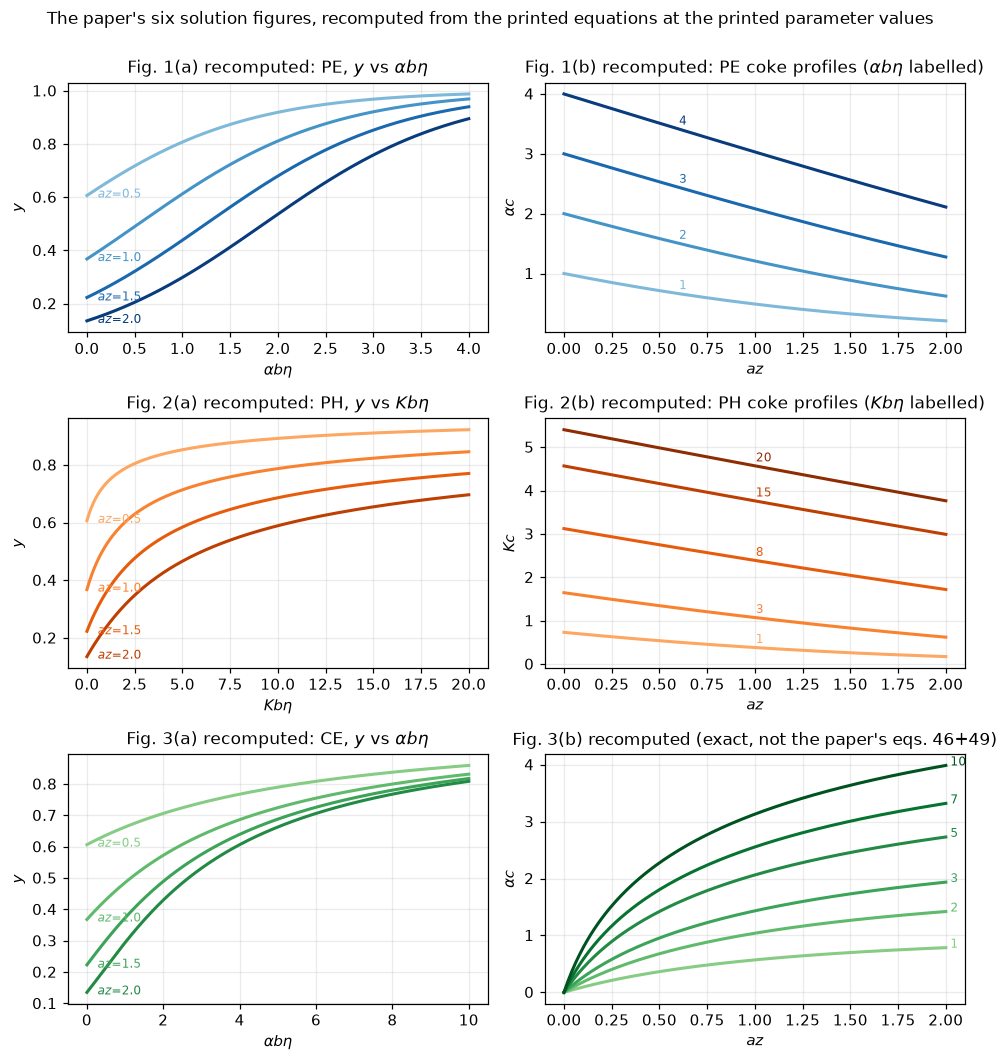

Parallel profiles DESCEND from the inlet; consecutive profiles ASCEND from exactly zero at the inlet (pure feed carries no product, so no consecutive coke forms at z = 0).


In [9]:
# The paper's Figs. 1-3, recomputed from the exact solutions (nothing digitised).
fig, ax = plt.subplots(3, 2, figsize=(9.0, 9.6))
xdepths = [0.5, 1.0, 1.5, 2.0]
shade = plt.cm.Blues(np.linspace(0.45, 0.95, 4))
greens = plt.cm.Greens(np.linspace(0.45, 0.95, 6))
oranges = plt.cm.Oranges(np.linspace(0.4, 0.95, 5))
xg = np.linspace(0, 2, 200)

Tg = np.linspace(0, 4, 300)
for xd, c in zip(xdepths, shade):
    ax[0, 0].plot(Tg, pe_exact(xd, Tg)[0], color=c, lw=2)
    ax[0, 0].annotate(f"$az$={xd}", (0.05, pe_exact(xd, 0.0)[0]), xytext=(4, -2),
                      textcoords="offset points", fontsize=8, color=c)
for Tv, c in zip([1, 2, 3, 4], shade):
    ax[0, 1].plot(xg, pe_exact(xg, Tv)[1], color=c, lw=2)
    ax[0, 1].annotate(f"{Tv}", (xg[60], pe_exact(xg[60], Tv)[1]), xytext=(0, 3),
                      textcoords="offset points", fontsize=8, color=c)
ax[0, 0].set(title="Fig. 1(a) recomputed: PE, $y$ vs $\\alpha b\\eta$", xlabel="$\\alpha b \\eta$", ylabel="$y$")
ax[0, 1].set(title="Fig. 1(b) recomputed: PE coke profiles ($\\alpha b\\eta$ labelled)",
             xlabel="$az$", ylabel="$\\alpha c$")

Tg = np.linspace(0, 20, 300)
for xd, c in zip(xdepths, oranges):
    ax[1, 0].plot(Tg, ph_exact(xd, Tg)[0], color=c, lw=2)
    ax[1, 0].annotate(f"$az$={xd}", (0.25, ph_exact(xd, 0.0)[0]), xytext=(4, -2),
                      textcoords="offset points", fontsize=8, color=c)
for Tv, c in zip([1, 3, 8, 15, 20], oranges):
    ax[1, 1].plot(xg, ph_exact(xg, Tv)[1], color=c, lw=2)
    ax[1, 1].annotate(f"{Tv}", (xg[100], ph_exact(xg[100], Tv)[1]), xytext=(0, 3),
                      textcoords="offset points", fontsize=8, color=c)
ax[1, 0].set(title="Fig. 2(a) recomputed: PH, $y$ vs $Kb\\eta$", xlabel="$Kb\\eta$", ylabel="$y$")
ax[1, 1].set(title="Fig. 2(b) recomputed: PH coke profiles ($Kb\\eta$ labelled)",
             xlabel="$az$", ylabel="$Kc$")

Tg = np.linspace(0.001, 10, 240)
yce_hist, _ = ce_exact(xdepths, Tg)
for i, (xd, c) in enumerate(zip(xdepths, greens)):
    ax[2, 0].plot(Tg, yce_hist[i], color=c, lw=2)
    ax[2, 0].annotate(f"$az$={xd}", (0.12, yce_hist[i, 0]), xytext=(4, -2),
                      textcoords="offset points", fontsize=8, color=c)
Tvals_ce = [1, 2, 3, 5, 7, 10]
_, Cce_prof = ce_exact(xg, Tvals_ce)
for j, (Tv, c) in enumerate(zip(Tvals_ce, greens)):
    ax[2, 1].plot(xg, Cce_prof[:, j], color=c, lw=2)
    ax[2, 1].annotate(f"{Tv}", (xg[-1], Cce_prof[-1, j]), xytext=(3, 0),
                      textcoords="offset points", fontsize=8, color=c)
ax[2, 0].set(title="Fig. 3(a) recomputed: CE, $y$ vs $\\alpha b\\eta$", xlabel="$\\alpha b \\eta$", ylabel="$y$")
ax[2, 1].set(title="Fig. 3(b) recomputed (exact, not the paper's eqs. 46+49)",
             xlabel="$az$", ylabel="$\\alpha c$")
for a in ax.ravel():
    a.grid(alpha=0.25)
fig.suptitle("The paper's six solution figures, recomputed from the printed equations "
             "at the printed parameter values", y=1.0)
fig.tight_layout()
plt.show()
print("Parallel profiles DESCEND from the inlet; consecutive profiles ASCEND from exactly zero "
      "at the inlet (pure feed carries no product, so no consecutive coke forms at z = 0).")

**Fig. 4 and the Voorhies exponents.** The paper computed
$\bar c$ by graphical integration of Figs. 1-3 and read slopes off a log-log
plot with a straightedge. Here $\bar c$ is a Simpson integral of the exact
solutions, and the local exponent is computed without a difference quotient:
$\mathrm{d}\ln\bar c/\mathrm{d}\ln T = T\,\bar c\,'(T)/\bar c$, where
$\bar c\,'$ is the bed average of the coke rate ($y$ for PE, $y/(1+W)$ for PH,
$1-y$ for CE). Every crossing below is root-found on that exponent.

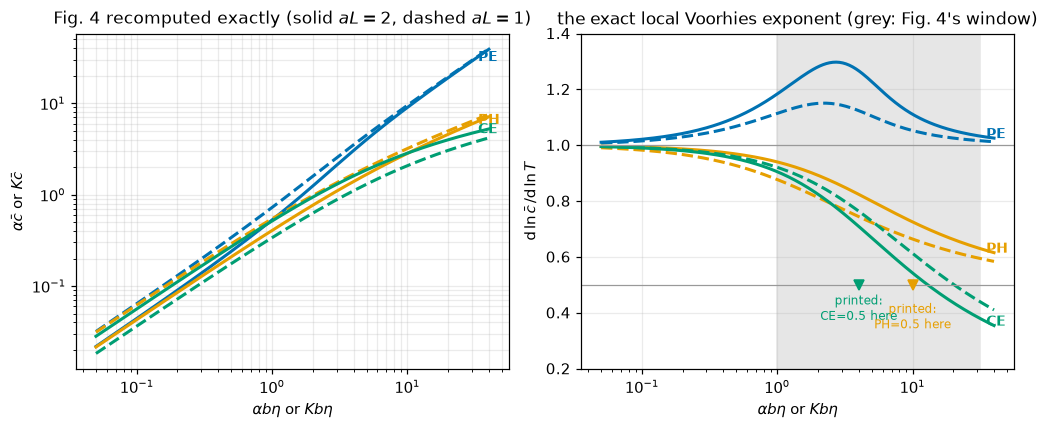


**Printed slope claims against the exact exponent** ($aL = 2$ unless stated):

| printed claim (Sec. 7a) | printed | computed exactly |
|---|---|---|
| all three mechanisms: slope at low $T$ | 1.0 | 0.9995 (mean over the six curves at $T = 0.05$; the limit is 1, since $c \propto T$ uniformly on a fresh bed) |
| PE "always approximately 1.0" | ~1.0 | 1.033 to 1.298 over the plotted window, always *above* 1 |
| CE "0.5 as $\alpha b\eta$ approaches 4 and beyond" | 0.5 at 4 | 0.710 at $T = 4$; the exponent has **no plateau**: it crosses 0.5 once, at $T = 12.97$ (20.34 at $aL = 1$), and keeps falling (asymptotically $\bar c \sim 2\ln T$, exponent $\to 0$) |
| PH "approaches 0.5 at about 10" | 0.5 at 10 | 0.726 at $T = 10$ (0.664 at $aL = 1$). 0.5 **is** the asymptote ($\bar c \sim s \sim \sqrt{2T}$: 0.507 at $T = 10^4$) but far from reached at 10 |

The low-$T$ limits and the PE statement reproduce; the two printed **onset values do not
survive exact computation**. They are chord readings on a short graphical window, and the
paper half-says so itself ("it seems that the experimental data are not accurate enough to
determine whether or not the slope gradually decreases as time progresses, as indicated by
Fig. 4").

**The Voorhies comparison, sharpened.** The paper quotes measured exponents
$n$ = 0.38-0.53 (Voorhies, gas-oil cracking), 0.65 (cyclohexane), 0.68
($n$-butane), 0.7 (reforming), and claims its mechanisms "lead to results that lie in
the range of the quoted experimental data". Computed exactly, the exponent over the plotted
window spans 1.033-1.298 for PE, 0.630-0.940 for PH and
0.380-0.905 for CE (each range taken at the window's ends, $T$ = 1 and
31.6): CE reaches 5 of the five quoted exponents, PH 3 (the upper
three) and PE 0, its exponent never dropping below 1. CE reaches the lowest, 0.38,
only at the window's end ($T = 31.5$), and its exponent keeps falling beyond it.
Within this model family the quoted data do not merely bracket the mechanisms: they point away
from parallel-exponential. The paper does not draw that conclusion; it is stated here as a
consequence of its own equations, not as a fact about the five experiments (which this page has
not seen).

**The space-time claim reproduces**: at $T = 5$, going from $aL = 1$ to $aL = 2$ moves
$\bar c$ from 4.505 to 4.015 (PE, decreases) and 1.979 to
1.669 (PH, decreases) but 1.304 to 1.871 (CE, increases):
the paper's Sec. 7(a) sign test for the mechanism from runs at two space times, exact.


In [10]:
T_GRID = np.geomspace(0.05, 40.0, 240)
CB, SL = {}, {}
for mech in ("PE", "PH", "CE"):
    for aL in (1, 2):
        CB[(mech, aL)], SL[(mech, aL)] = cbar_slope(mech, aL, T_GRID)


def slope(mech, aL, T):
    """The exact local Voorhies exponent at one time."""
    return float(cbar_slope(mech, aL, [T])[1][0])


W_LO, W_HI = 1.0, 31.6                   # Fig. 4's plotted window


def window_extrema(mech, aL=2):
    """Smallest and largest exponent on Fig. 4's window: a scan, refined on the curve."""
    Ts = np.geomspace(W_LO, W_HI, 200)
    s = cbar_slope(mech, aL, Ts)[1]
    out = []
    for sign, i in ((1.0, int(np.argmin(s))), (-1.0, int(np.argmax(s)))):
        if 0 < i < Ts.size - 1:
            r = minimize_scalar(lambda lt: sign * slope(mech, aL, np.exp(lt)),
                                bounds=(np.log(Ts[i - 1]), np.log(Ts[i + 1])), method="bounded",
                                options={"xatol": 1e-10})
            out.append((sign * r.fun, float(np.exp(r.x))))
        else:
            out.append((float(s[i]), float(Ts[i])))         # an extremum at the window's edge
    return out


EXT = {m: window_extrema(m) for m in ("PE", "PH", "CE")}
T_LOW = T_GRID[0]
claims.value("slope_low_T_all", np.mean([SL[k][0] for k in SL]), rtol=1e-6,
             note="mean of the six exponents at T = 0.05")
brk("exponent read at T = 1 instead of 0.05", "slope_low_T_all",
    np.mean([slope(m, a, 1.0) for m in ("PE", "PH", "CE") for a in (1, 2)]))
for mech in ("PE", "PH", "CE"):
    (lo, t_lo), (hi, t_hi) = EXT[mech]
    claims.value(f"{mech.lower()}_slope_min_aL2", lo, rtol=1e-6)
    claims.value(f"{mech.lower()}_slope_max_aL2", hi, rtol=1e-6)
_swap = {"PE": "PH", "PH": "CE", "CE": "PE"}
for mech in ("PE", "PH", "CE"):
    (lo, _), (hi, _) = EXT[_swap[mech]]
    brk(f"{_swap[mech]} cbar read as {mech} (mechanism swapped)", f"{mech.lower()}_slope_min_aL2", lo)
    brk(f"{_swap[mech]} cbar read as {mech} (mechanism swapped)", f"{mech.lower()}_slope_max_aL2", hi)
claims.value("ph_slope_at_T10_aL2", slope("PH", 2, 10.0), rtol=1e-6)
claims.value("ph_slope_at_T10_aL1", slope("PH", 1, 10.0), rtol=1e-6)
claims.value("ce_slope_at_T4_aL2", slope("CE", 2, 4.0), rtol=1e-6)
brk("PE cbar read as CE (mechanism swapped)", "ce_slope_at_T4_aL2", slope("PE", 2, 4.0))
brk("PE cbar read as PH (mechanism swapped)", "ph_slope_at_T10_aL2", slope("PE", 2, 10.0))
brk("PE cbar read as PH (mechanism swapped)", "ph_slope_at_T10_aL1", slope("PE", 1, 10.0))
CROSS = {}
for aL in (1, 2):
    r = find_roots(lambda T: slope("CE", aL, T) - 0.5, 1.0, 40.0, n_scan=40, log=True, xtol=1e-10)
    CROSS[aL] = r["roots"]
claims.exact("ce_slope_crosses_05_once", len(CROSS[1]) == 1 and len(CROSS[2]) == 1,
             note="one sign change of exponent - 0.5 on T in [1, 40] at aL = 1 and 2")
brk("PH exponent searched for 0.5 instead of CE (it does not reach it on [1, 40])",
    "ce_slope_crosses_05_once",
    len(find_roots(lambda T: slope("PH", 2, T) - 0.5, 1.0, 40.0, n_scan=40, log=True)["roots"]) == 1)
claims.value("ce_slope_cross_05_T_aL2", CROSS[2][0], rtol=1e-6)
claims.value("ce_slope_cross_05_T_aL1", CROSS[1][0], rtol=1e-6)
brk("crossing of 0.6 located instead of 0.5", "ce_slope_cross_05_T_aL2",
    find_roots(lambda T: slope("CE", 2, T) - 0.6, 1.0, 40.0, n_scan=40, log=True)["roots"][0])
brk("crossing of 0.6 located instead of 0.5", "ce_slope_cross_05_T_aL1",
    find_roots(lambda T: slope("CE", 1, T) - 0.6, 1.0, 40.0, n_scan=40, log=True)["roots"][0])
claims.value("ph_slope_asymptote_check_T1e4", slope("PH", 2, 1e4), rtol=1e-6)
brk("PH exponent read at T = 1e3 instead of 1e4", "ph_slope_asymptote_check_T1e4", slope("PH", 2, 1e3))
CE_038 = find_roots(lambda T: slope("CE", 2, T) - PRINTED.loc["voorhies_n_low", "printed_value"],
                    5.0, 100.0, n_scan=40, log=True)["roots"]

# the quoted measured exponents against the window's range of each mechanism
NQ = PRINTED.loc[["voorhies_n_low", "voorhies_n_high", "n_rudershausen_watson", "n_tyuryaev",
                  "n_wilson_denherder"], "printed_value"].to_numpy(float)
REACH = {}
for mech in ("PE", "PH", "CE"):
    (lo, _), (hi, _) = EXT[mech]
    inside = (NQ >= lo) & (NQ <= hi)
    margin = float(np.min(np.minimum(np.abs(NQ - lo), np.abs(NQ - hi))))
    REACH[mech] = int(inside.sum())
    claims.exact(f"voorhies_reachable_{mech}", REACH[mech], margin=margin, min_margin=1e-6,
                 note="quoted exponents inside [min, max] of the exponent on Fig. 4's window")
for mech in ("PE", "PH", "CE"):
    (lo, _), (hi, _) = EXT[_swap[mech]]
    brk(f"{_swap[mech]} exponent range used for {mech}", f"voorhies_reachable_{mech}",
        int(((NQ >= lo) & (NQ <= hi)).sum()))

# space-time claim (Sec. 7a): cbar against aL at T = 5, exactly at T = 5
ST = {m: (float(cbar_slope(m, 1, [5.0])[0][0]), float(cbar_slope(m, 2, [5.0])[0][0]))
      for m in ("PE", "PH", "CE")}
T_NEAR = float(T_GRID[np.argmin(np.abs(T_GRID - 5.0))])
for m in ("PE", "PH", "CE"):
    for i, aL in enumerate((1, 2)):
        name = f"spacetime_{m.lower()}_cbar_aL{aL}_T5"
        claims.value(name, ST[m][i], rtol=1e-6)
        brk(f"cbar read at the grid point nearest T = 5 (T = {T_NEAR:.3f})", name,
            float(cbar_slope(m, aL, [T_NEAR])[0][0]))
for m in ("PE", "PH", "CE"):
    d = ST[m][1] - ST[m][0]
    claims.exact(f"spacetime_{m.lower()}_increases", bool(d > 0), margin=abs(d) / ST[m][0], min_margin=1e-6)
    brk(f"aL = 0.5 in place of aL = 2 ({m})", f"spacetime_{m.lower()}_increases",
        bool(float(cbar_slope(m, 0.5, [5.0])[0][0]) - ST[m][0] > 0))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.4, 4.0))
for (m, aL), v in CB.items():
    a1.loglog(T_GRID, v, color=COL[m], lw=2, ls="-" if aL == 2 else "--")
for m in ("PE", "PH", "CE"):
    a1.annotate(m, (30, np.interp(30, T_GRID, CB[(m, 2)])), color=COL[m], fontsize=9,
                fontweight="bold", xytext=(4, 0), textcoords="offset points")
a1.set(xlabel=r"$\alpha b\eta$ or $Kb\eta$", ylabel=r"$\alpha\bar c$ or $K\bar c$",
       title="Fig. 4 recomputed exactly (solid $aL=2$, dashed $aL=1$)")
a1.grid(alpha=0.25, which="both")
for (m, aL), v in SL.items():
    a2.semilogx(T_GRID, v, color=COL[m], lw=2, ls="-" if aL == 2 else "--")
a2.axhline(1.0, color="0.6", lw=0.8)
a2.axhline(0.5, color="0.6", lw=0.8)
a2.axvspan(W_LO, W_HI, color="0.9", zorder=0)
for m, Tp in (("CE", PRINTED.loc["slope_ce_half_at", "printed_value"]),
              ("PH", PRINTED.loc["slope_ph_half_at", "printed_value"])):
    a2.plot([Tp], [0.5], "v", color=COL[m], ms=7)
    a2.annotate(f"printed:\n{m}=0.5 here", (Tp, 0.47 if m == "CE" else 0.44), fontsize=8,
                color=COL[m], ha="center", va="top")
for m in ("PE", "PH", "CE"):
    a2.annotate(m, (35, SL[(m, 2)][-1]), color=COL[m], fontsize=9, fontweight="bold")
a2.set(xlabel=r"$\alpha b\eta$ or $Kb\eta$", ylabel=r"d$\,\ln\bar c\,$/d$\,\ln T$",
       ylim=(0.2, 1.4), title="the exact local Voorhies exponent (grey: Fig. 4's window)")
a2.grid(alpha=0.25)
fig.tight_layout()
plt.show()

(pe_lo, _), (pe_hi, _) = EXT["PE"]
(ph_lo, ph_lo_T), (ph_hi, ph_hi_T) = EXT["PH"]
(ce_lo, ce_lo_T), (ce_hi, ce_hi_T) = EXT["CE"]
display(Markdown(f"""
**Printed slope claims against the exact exponent** ($aL = 2$ unless stated):

| printed claim (Sec. 7a) | printed | computed exactly |
|---|---|---|
| all three mechanisms: slope at low $T$ | {PRINTED.loc['slope_pe', 'printed_value']:.1f} | {claims['slope_low_T_all']:.4f} (mean over the six curves at $T = {T_LOW:g}$; the limit is 1, since $c \\propto T$ uniformly on a fresh bed) |
| PE "always approximately 1.0" | ~{PRINTED.loc['slope_pe', 'printed_value']:.1f} | {pe_lo:.3f} to {pe_hi:.3f} over the plotted window, always *above* 1 |
| CE "0.5 as $\\alpha b\\eta$ approaches 4 and beyond" | 0.5 at {PRINTED.loc['slope_ce_half_at', 'printed_value']:g} | {claims['ce_slope_at_T4_aL2']:.3f} at $T = 4$; the exponent has **no plateau**: it crosses 0.5 once, at $T = {claims['ce_slope_cross_05_T_aL2']:.2f}$ ({claims['ce_slope_cross_05_T_aL1']:.2f} at $aL = 1$), and keeps falling (asymptotically $\\bar c \\sim 2\\ln T$, exponent $\\to 0$) |
| PH "approaches 0.5 at about 10" | 0.5 at {PRINTED.loc['slope_ph_half_at', 'printed_value']:g} | {claims['ph_slope_at_T10_aL2']:.3f} at $T = 10$ ({claims['ph_slope_at_T10_aL1']:.3f} at $aL = 1$). 0.5 **is** the asymptote ($\\bar c \\sim s \\sim \\sqrt{{2T}}$: {claims['ph_slope_asymptote_check_T1e4']:.3f} at $T = 10^4$) but far from reached at 10 |

The low-$T$ limits and the PE statement reproduce; the two printed **onset values do not
survive exact computation**. They are chord readings on a short graphical window, and the
paper half-says so itself ("it seems that the experimental data are not accurate enough to
determine whether or not the slope gradually decreases as time progresses, as indicated by
Fig. 4").

**The Voorhies comparison, sharpened.** The paper quotes measured exponents
$n$ = {NQ[0]:g}-{NQ[1]:g} (Voorhies, gas-oil cracking), {NQ[2]:g} (cyclohexane), {NQ[3]:g}
($n$-butane), {NQ[4]:g} (reforming), and claims its mechanisms "lead to results that lie in
the range of the quoted experimental data". Computed exactly, the exponent over the plotted
window spans {pe_lo:.3f}-{pe_hi:.3f} for PE, {ph_lo:.3f}-{ph_hi:.3f} for PH and
{ce_lo:.3f}-{ce_hi:.3f} for CE (each range taken at the window's ends, $T$ = {W_LO:g} and
{W_HI:g}): CE reaches {REACH['CE']} of the five quoted exponents, PH {REACH['PH']} (the upper
three) and PE {REACH['PE']}, its exponent never dropping below 1. CE reaches the lowest, {NQ[0]:g},
only at the window's end ($T = {CE_038[0]:.1f}$), and its exponent keeps falling beyond it.
Within this model family the quoted data do not merely bracket the mechanisms: they point away
from parallel-exponential. The paper does not draw that conclusion; it is stated here as a
consequence of its own equations, not as a fact about the five experiments (which this page has
not seen).

**The space-time claim reproduces**: at $T = 5$, going from $aL = 1$ to $aL = 2$ moves
$\\bar c$ from {ST['PE'][0]:.3f} to {ST['PE'][1]:.3f} (PE, decreases) and {ST['PH'][0]:.3f} to
{ST['PH'][1]:.3f} (PH, decreases) but {ST['CE'][0]:.3f} to {ST['CE'][1]:.3f} (CE, increases):
the paper's Sec. 7(a) sign test for the mechanism from runs at two space times, exact.
"""))

**Fig. 5 and the travelling hot spot.** The ridge of the rate surface
$r' = y e^{-C}$ (eqs. 53-54) has a closed form the paper does not print.
Setting $\mathrm{d}\ln r'/\mathrm{d}x = 0$ in eq. (54) gives $e^x = e^T - 1$
exactly, so $x^{\ast}(T) = \ln(e^T - 1) \to T$: the locus of maximum rate (and
maximum heat release) enters the bed at $T = \ln 2$ and travels with unit
speed in $(x, T)$, i.e. $\mathrm{d}z^{\ast}/\mathrm{d}\eta = \alpha b/a$, and the
rate on the ridge is $(1 + 1/(e^T - 1))/4 \to 1/4$ of the fresh inlet rate.

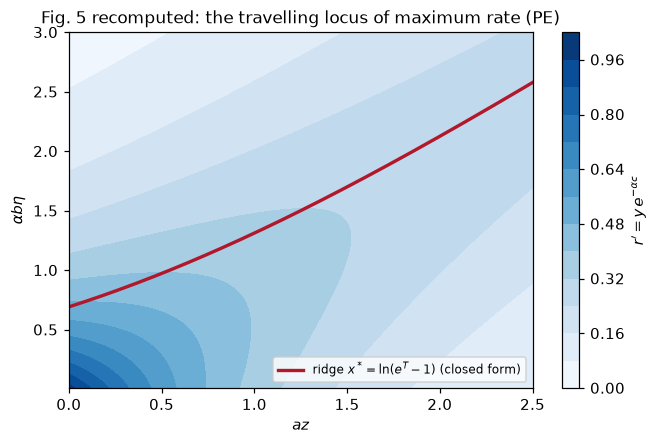

ridge at T = 2: maximiser x = 1.854587 against ln(e^2 - 1) = 1.854587 (gap below 1e-7, here 7e-09); rate on the ridge 0.289129 against (1 + 1/(e^2 - 1))/4 (gap below 1e-12, here 0e+00)
This is Sec. 7(b) made quantitative: with a descending coke profile the hot spot MOVES; a control scheme tuned to the fresh-bed profile chases it.


In [11]:
Tg = np.linspace(0.01, 3.0, 320)
xgs = np.linspace(0.0, 2.5, 320)
Xm, Tm = np.meshgrid(xgs, Tg)
y_s5, C_s5 = pe_exact(Xm, Tm)
Rp = y_s5 * np.exp(-C_s5)
fig, axf = plt.subplots(figsize=(6.8, 4.2))
cf = axf.contourf(Xm, Tm, Rp, levels=14, cmap="Blues")
fig.colorbar(cf, label="$r' = y\\,e^{-\\alpha c}$")
Tr = Tg[Tg > np.log(2) + 1e-9]
axf.plot(np.log(np.expm1(Tr)), Tr, color="#B2182B", lw=2.2, label="ridge $x^*=\\ln(e^T-1)$ (closed form)")
axf.set(xlabel="$az$", ylabel="$\\alpha b\\eta$", xlim=(0, 2.5),
        title="Fig. 5 recomputed: the travelling locus of maximum rate (PE)")
axf.legend(loc="lower right", fontsize=8)
plt.show()


def rate_pe(x, T):
    y, C = pe_exact(x, T)
    return float(y * np.exp(-C))


RIDGE = minimize_scalar(lambda x: -rate_pe(x, 2.0), bounds=(0.0, 2.5), method="bounded",
                        options={"xatol": 1e-12})
X_STAR2 = np.log(np.expm1(2.0))
claims.bound("ridge_locus_num_vs_closed_T2", abs(RIDGE.x - X_STAR2), max=1e-7, basis="tolerance",
             note="bounded minimiser, xatol 1e-12; at a flat maximum the abscissa is fixed only to "
                  "about the square root of the rate's accuracy")
claims.bound("ridge_rate_vs_closed_T2", abs(-RIDGE.fun - (1 + 1 / np.expm1(2.0)) / 4), max=1e-12,
             basis="tolerance", note="rate at the located maximum against (1 + 1/(e^T - 1))/4")
_i2 = int(np.argmin(np.abs(Tg - 2.0)))
brk(f"maximum read off the plotted 320 x 320 grid (row T = {Tg[_i2]:.4f})", "ridge_locus_num_vs_closed_T2",
    abs(xgs[np.argmax(Rp[_i2])] - X_STAR2))
brk(f"maximum read off the plotted 320 x 320 grid (row T = {Tg[_i2]:.4f})", "ridge_rate_vs_closed_T2",
    abs(Rp[_i2].max() - (1 + 1 / np.expm1(2.0)) / 4))
print(f"ridge at T = 2: maximiser x = {RIDGE.x:.6f} against ln(e^2 - 1) = {X_STAR2:.6f} "
      f"(gap below 1e-7, here {claims['ridge_locus_num_vs_closed_T2']:.0e}); rate on the ridge "
      f"{-RIDGE.fun:.6f} against (1 + 1/(e^2 - 1))/4 (gap below 1e-12, here "
      f"{claims['ridge_rate_vs_closed_T2']:.0e})")
print("This is Sec. 7(b) made quantitative: with a descending coke profile the hot spot MOVES; "
      "a control scheme tuned to the fresh-bed profile chases it.")

**The profile diagnostic, taken seriously: when can a carbon assay tell the
mechanisms apart?** The measure is the half-bed contrast
$\Delta_h = (\bar c_\mathrm{rear} - \bar c_\mathrm{front})/\bar c$, what the
crudest sectioned regeneration experiment estimates; the half-bed means are
Simpson integrals of the exact profile over each half. With a relative error
$\sigma$ on each half's carbon assay, the difference resolves only if
$|\Delta_h| > 2\sqrt{2}\,\sigma$ (two sigma on a difference of two
independent assays). The paper says which *sign* each mechanism gives; this
cell computes the magnitude, where it dies, and what the mixed mechanism does
to it.

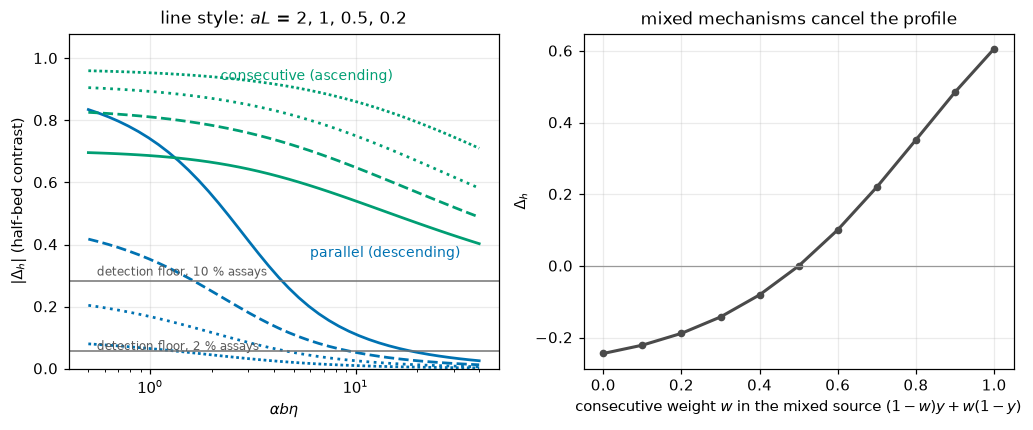


**At the paper's own operating point** ($aL = 2$, $\alpha b\eta = 5$): the consecutive profile
carries a half-bed contrast of +0.606, detectable with assays as
poor as $\sigma \approx 21.4$ %, while the parallel
profile carries only -0.244, needing
$\sigma \lesssim 8.6$ %: **with routine 10 % carbon
assays and a two-section cut, the descending profile of the parallel mechanism is already
invisible at the paper's own conditions**, and it fades further with time on stream
(-0.0526 at $T = 20$; asymptotically the whole profile flattens to
slope $-1$ and the end-to-end contrast obeys $-aL/(T - aL/2)$, which the exact integral meets to
below 1e-8, here 7e-10).

The ascending consecutive signature fades too, but only logarithmically: its contrast is
+0.469 at $T = 20$, +0.330 at
$10^2$, +0.214 at $10^3$ and +0.154
at $10^4$ (the coke grows like $2\ln T$ everywhere, so the contrast falls roughly as $1/\ln T$).
The assay it needs tightens from 21.4 % at $T = 5$ to
16.6 % at 20 and 7.6 %
at $10^3$; it drops below a 20 % assay floor at $T = 7.78$.
What never fades is the inlet anchor: $c(0) = 0$ exactly, at every $T$, because pure feed carries
no product. So the paper's Sec. 7(a) verdict ("what is needed are careful experiments in which the
carbon profile is actually measured") has a quantitative edge: profile measurement mainly *rules
in* a consecutive route; failing to see a descending profile rules out little.

**The degenerate case is exact.** With both routes first order and equal weight ($w = 1/2$), the
coke source $(1-w)y + w(1-y)$ is $\tfrac12$ whatever $y$ is, so the profile is *identically* flat
(the bed gives $|\Delta_h|$ below 1e-12, here 0e+00) while
$\bar c = T/2$ grows smoothly and, being independent of $aL$, is also independent of space time:
the paper's own remark about balancing mechanisms, made exact. A flat profile with a clean
Voorhies curve is therefore *not* evidence of uniform aging chemistry.


In [12]:
FLOOR = 2.0 * np.sqrt(2.0)                    # |Delta_h| > FLOOR * sigma resolves the profile
Tscan = np.geomspace(0.5, 40, 40)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.4, 4.0))
for aL, ls in ((2.0, "-"), (1.0, "--"), (0.5, ":"), (0.2, (0, (1, 1)))):
    for mech in ("PE", "CE"):
        a1.semilogx(Tscan, [abs(half_contrast(mech, aL, T, nx=201)) for T in Tscan],
                    color=COL[mech], ls=ls, lw=1.8)
for sig, lab in ((0.10, "10 % assays"), (0.02, "2 % assays")):
    a1.axhline(FLOOR * sig, color="0.45", lw=1.0)
    a1.annotate(f"detection floor, {lab}", (0.55, FLOOR * sig * 1.06), fontsize=8, color="0.35")
a1.annotate("consecutive (ascending)", (2.2, 0.93), color=COL["CE"], fontsize=9)
a1.annotate("parallel (descending)", (6.0, 0.36), color=COL["PE"], fontsize=9)
a1.set(xlabel=r"$\alpha b\eta$", ylabel=r"$|\Delta_h|$ (half-bed contrast)",
       title="line style: $aL$ = 2, 1, 0.5, 0.2", ylim=(0, 1.08))
a1.grid(alpha=0.25)


def mixed_contrast(w, aL=2.0, T=5.0, n=160, m=120):
    """Half-bed contrast of the coke laid down by the mixed source on the pymrm bed."""
    bed = Bed("MIX", L=aL, n=n, w_mix=w)
    bed.march(T, m)
    return contrast_of_profile(bed.C, bed.x_c, rule="cells")


W_GRID = np.linspace(0, 1, 11)
DH_MIX = [mixed_contrast(w) for w in W_GRID]
a2.plot(W_GRID, DH_MIX, color="#4a4a4a", lw=2, marker="o", ms=4)
a2.axhline(0, color="0.6", lw=0.8)
a2.set(xlabel="consecutive weight $w$ in the mixed source $(1-w)y + w(1-y)$", ylabel=r"$\Delta_h$",
       title="mixed mechanisms cancel the profile")
a2.grid(alpha=0.25)
fig.tight_layout()
plt.show()


def node_average_contrast(mech, aL, T):
    """Half-bed means as plain averages over 400 equally spaced nodes (a defect row)."""
    xgr = np.linspace(0, aL, 400)
    C = pe_exact(xgr, T)[1] if mech == "PE" else ce_exact(xgr, [T])[1][:, 0]
    return (C[200:].mean() - C[:200].mean()) / (simpson(C, x=xgr) / aL)


DIAG = {"diag_halfcontrast_pe_base": ("PE", 5.0), "diag_halfcontrast_ce_base": ("CE", 5.0),
        "diag_halfcontrast_pe_T20": ("PE", 20.0), "diag_halfcontrast_ce_T20": ("CE", 20.0),
        "diag_halfcontrast_ce_T1e2": ("CE", 1e2), "diag_halfcontrast_ce_T1e3": ("CE", 1e3),
        "diag_halfcontrast_ce_T1e4": ("CE", 1e4)}
DH = {}
for name, (mech, T) in DIAG.items():
    DH[name] = half_contrast(mech, 2.0, T)
    claims.value(name, DH[name], rtol=1e-6)
    brk("half-bed means as averages over 400 nodes", name, node_average_contrast(mech, 2.0, T))
brk("mechanism swapped: the consecutive contrast read off the parallel profile",
    "diag_halfcontrast_ce_base", half_contrast("PE", 2.0, 5.0))
SIG = {"diag_sigma_max_pe_base": DH["diag_halfcontrast_pe_base"],
       "diag_sigma_max_ce_base": DH["diag_halfcontrast_ce_base"],
       "diag_sigma_max_ce_T20": DH["diag_halfcontrast_ce_T20"],
       "diag_sigma_max_ce_T1e3": DH["diag_halfcontrast_ce_T1e3"]}
for name, d in SIG.items():
    claims.value(name, abs(d) / FLOOR, rtol=1e-6)
    brk("floor of two sigma on one assay (factor 2) instead of a difference of two", name, abs(d) / 2.0)


def floor_crossing(sigma):
    """Coking time at which the consecutive signature drops to the floor of sigma-assays."""
    return find_roots(lambda T: abs(half_contrast("CE", 2.0, T)) / FLOOR - sigma, 2.0, 1e3,
                      n_scan=30, log=True, xtol=1e-8)["roots"]


CROSS20 = floor_crossing(0.20)
claims.exact("diag_ce_floor20_crosses_once", len(CROSS20), note="one root on [2, 1000]")
claims.value("diag_ce_floor20_crossing_T", CROSS20[0], rtol=1e-6)
brk("floor of 10 % assays located instead of 20 %", "diag_ce_floor20_crossing_T", floor_crossing(0.10)[0])
brk("floor of 25 % assays located instead of 20 % (none on [2, 1000])", "diag_ce_floor20_crosses_once",
    len(floor_crossing(0.25)))

# end-to-end PE contrast against its large-T asymptote -aL/(T - aL/2)
xgr = np.linspace(0, 2, 801)


def end_contrast_gap(T):
    C = pe_exact(xgr, T)[1]
    return abs((C[-1] - C[0]) / (simpson(C, x=xgr) / 2) + 2.0 / (T - 1.0))


claims.bound("diag_endcontrast_pe_T20_vs_asymptote", end_contrast_gap(20.0), max=1e-8, basis="theory",
             note="the asymptote drops terms of order exp(-(T - aL)), about 1.5e-8 at T = 20")
brk("asymptote compared at T = 5 instead of 20", "diag_endcontrast_pe_T20_vs_asymptote", end_contrast_gap(5.0))
claims.bound("mixed_w05_halfcontrast", abs(DH_MIX[5]), max=1e-12, basis="identity", structural=True,
             note="at w = 1/2 the coke source is 1/2 whatever y is, so C = T/2 everywhere")

display(Markdown(f"""
**At the paper's own operating point** ($aL = 2$, $\\alpha b\\eta = 5$): the consecutive profile
carries a half-bed contrast of {DH['diag_halfcontrast_ce_base']:+.3f}, detectable with assays as
poor as $\\sigma \\approx {100 * claims['diag_sigma_max_ce_base']:.1f}$ %, while the parallel
profile carries only {DH['diag_halfcontrast_pe_base']:+.3f}, needing
$\\sigma \\lesssim {100 * claims['diag_sigma_max_pe_base']:.1f}$ %: **with routine 10 % carbon
assays and a two-section cut, the descending profile of the parallel mechanism is already
invisible at the paper's own conditions**, and it fades further with time on stream
({DH['diag_halfcontrast_pe_T20']:+.4f} at $T = 20$; asymptotically the whole profile flattens to
slope $-1$ and the end-to-end contrast obeys $-aL/(T - aL/2)$, which the exact integral meets to
below 1e-8, here {claims['diag_endcontrast_pe_T20_vs_asymptote']:.0e}).

The ascending consecutive signature fades too, but only logarithmically: its contrast is
{DH['diag_halfcontrast_ce_T20']:+.3f} at $T = 20$, {DH['diag_halfcontrast_ce_T1e2']:+.3f} at
$10^2$, {DH['diag_halfcontrast_ce_T1e3']:+.3f} at $10^3$ and {DH['diag_halfcontrast_ce_T1e4']:+.3f}
at $10^4$ (the coke grows like $2\\ln T$ everywhere, so the contrast falls roughly as $1/\\ln T$).
The assay it needs tightens from {100 * claims['diag_sigma_max_ce_base']:.1f} % at $T = 5$ to
{100 * claims['diag_sigma_max_ce_T20']:.1f} % at 20 and {100 * claims['diag_sigma_max_ce_T1e3']:.1f} %
at $10^3$; it drops below a 20 % assay floor at $T = {claims['diag_ce_floor20_crossing_T']:.2f}$.
What never fades is the inlet anchor: $c(0) = 0$ exactly, at every $T$, because pure feed carries
no product. So the paper's Sec. 7(a) verdict ("what is needed are careful experiments in which the
carbon profile is actually measured") has a quantitative edge: profile measurement mainly *rules
in* a consecutive route; failing to see a descending profile rules out little.

**The degenerate case is exact.** With both routes first order and equal weight ($w = 1/2$), the
coke source $(1-w)y + w(1-y)$ is $\\tfrac12$ whatever $y$ is, so the profile is *identically* flat
(the bed gives $|\\Delta_h|$ below 1e-12, here {claims['mixed_w05_halfcontrast']:.0e}) while
$\\bar c = T/2$ grows smoothly and, being independent of $aL$, is also independent of space time:
the paper's own remark about balancing mechanisms, made exact. A flat profile with a clean
Voorhies curve is therefore *not* evidence of uniform aging chemistry.
"""))

## Validation

No measurement exists in the source, so everything here is **reproduction and
internal consistency**, structured so that each number can fail:

1. the three analytic references are cross-checked against *each other*
   (closed forms against the eq.-29 ODE route; the CE reduction against the
   paper's own series, symbolically) before the bed is judged against them;
2. the pymrm bed is then refined in both axes, jointly and one at a time,
   through the ridge passage, with the observed orders printed;
3. the paper's four approximations are measured against the exact solutions,
   which turns its prose claims (the 5 % / $\gamma \le 0.02$ statement, the
   series window, the "improves as $\eta$ increases" assertion, $\eta \simeq t$)
   into numbers that could have come out wrong;
4. every claim has a break-table row that fails its own check, and the checks
   that *cannot* move are labelled structural.

**The pymrm bed against the three exact references.** The error is the
max-norm over the cells and over profiles recorded at five times spanning the
ridge passage (the PE ridge enters the bed at $T = \ln 2$ and leaves $x = 2$
at $T = \ln(e^2 + 1)$, inside every record window used here).

In [13]:
T_END = {"PE": 5.0, "PH": 10.0, "CE": 5.0}
JOINT = {"PE": ((50, 60), (100, 120), (200, 240), (400, 480)),
         "PH": ((50, 60), (100, 120), (200, 240), (400, 480)),
         "CE": ((50, 60), (100, 120), (200, 240), (400, 480), (800, 960))}
ORDER_BOUNDS = {"PE": (1.95, 2.05, "theory", None), "PH": (1.95, 2.2, "chosen",
                "second order; the coarsest pair of the C error is pre-asymptotic (2.16)"),
                "CE": (1.7, 2.05, "chosen", "pre-asymptotic, rising with n: the error peaks in the "
                       "first cells, where the coke rises from zero at the inlet")}
ERR, ORD, TOP = {}, {}, {}
for mech, rungs in JOINT.items():
    out = [err_vs_exact(mech, T_END[mech], n, m, return_bed=True) for n, m in rungs]
    ERR[mech] = [(ey, eC) for ey, eC, _ in out]
    TOP[mech] = out[-1][2]
    ORD[mech] = {k: [np.log2(ERR[mech][i][k] / ERR[mech][i + 1][k]) for i in range(len(rungs) - 1)]
                 for k in (0, 1)}
    for (n, m), (ey, eC) in zip(rungs, ERR[mech]):
        if n >= 400:
            claims.value(f"{mech.lower()}_maxerr_y_n{n}", ey)
            claims.value(f"{mech.lower()}_maxerr_C_n{n}", eC)
    lo, hi, basis, note = ORDER_BOUNDS[mech]
    for k, f in ((0, "y"), (1, "C")):
        claims.bound(f"{mech.lower()}_order_{f}_min", min(ORD[mech][k]), min=lo, max=hi, basis=basis, note=note)
        claims.bound(f"{mech.lower()}_order_{f}_max", max(ORD[mech][k]), min=lo, max=hi, basis=basis, note=note)
claims.exact("ce_orders_rise", bool(np.all(np.diff(ORD["CE"][0]) > 0)),
             margin=float(np.min(np.diff(ORD["CE"][0]))), min_margin=1e-3,
             note="each refinement raises the observed order of the CE error in y")

# the round-off of the finest errors: the same march by the deferred-correction route
GAP = {}
for mech, rungs in JOINT.items():
    n, m = rungs[-1]
    bd = Bed(mech, n=n, route="deferred", tol=1e-13)
    bd.march(T_END[mech], m)
    GAP[mech] = float(np.abs(bd.C - TOP[mech].C).max())
claims.bound("march_newton_vs_deferred", max(GAP.values()), max=1e-10, basis="tolerance",
             note="final coke profiles on the finest rung of each joint ladder; newton step tol 1e-12, "
                  "sweeps to a change below 1e-13")
RATIO = min(ERR[m][-1][1] / max(GAP[m], 1e-16) for m in JOINT)
claims.bound("joint_finest_over_roundoff", RATIO, min=1e3, basis="theory",
             note="finest error in C over the two-route gap of the same march")
_bl = Bed("PE", n=400, route="deferred", tol=1e-4)
_bl.march(5.0, 480)
_gap_loose = float(np.abs(_bl.C - TOP["PE"].C).max())
brk("deferred sweeps stopped at a change of 1e-4", "march_newton_vs_deferred", _gap_loose)
brk("deferred sweeps stopped at a change of 1e-4", "joint_finest_over_roundoff",
    ERR["PE"][-1][1] / _gap_loose)

# break rows on the bed, each run on the rung its claim is read on
for mech, rungs in JOINT.items():
    for n, m in rungs:
        if n >= 400:
            ey, eC = err_vs_exact(mech, T_END[mech], n, m, y_in=0.9)
            brk("feed y = 0.9 instead of pure feed (Bed(..., y_in=0.9))", f"{mech.lower()}_maxerr_y_n{n}", ey)
            brk("feed y = 0.9 instead of pure feed (Bed(..., y_in=0.9))", f"{mech.lower()}_maxerr_C_n{n}", eC)
    eu = [err_vs_exact(mech, T_END[mech], nn, mm, scheme="euler") for nn, mm in rungs[:4]]
    for k, f in ((0, "y"), (1, "C")):
        o = [np.log2(eu[i][k] / eu[i + 1][k]) for i in range(3)]
        brk("forward Euler in T instead of Heun (march(..., scheme='euler'))", f"{mech.lower()}_order_{f}_min", min(o))
        brk("forward Euler in T instead of Heun (march(..., scheme='euler'))", f"{mech.lower()}_order_{f}_max", max(o))
        if mech == "CE" and k == 0:
            brk("forward Euler in T instead of Heun, CE, 50 to 400 cells", "ce_orders_rise",
                bool(np.all(np.diff(o) > 0)))
_eu_ce = [err_vs_exact("CE", 5.0, nn, mm, limiter=None) for nn, mm in JOINT["CE"][:4]]
_o_ce = [np.log2(_eu_ce[i][0] / _eu_ce[i + 1][0]) for i in range(3)]
brk("first-order upwind convection (limiter=None), CE, 50 to 400 cells", "ce_orders_rise",
    bool(np.all(np.diff(_o_ce) > 0)))
_sign = err_vs_exact("PE", 5.0, 400, 480, activity=lambda C: np.exp(+C))
brk("activity sign flipped, phi = exp(+alpha c) (Bed(..., activity=...))", "pe_maxerr_y_n400", _sign[0])
_off = err_vs_exact("PE", 5.0, 400, 466, on_grid=False)
brk("profiles recorded at the first step past each target time (466 steps)", "pe_maxerr_C_n400", _off[1])

# the cause of CE's lower orders, tested one ingredient at a time
CE_X = [err_vs_exact("CE", 5.0, n, 1920)[0] for n in (50, 100, 200, 400)]
def lin_upwind(c, x_c, x_d):
    """Unlimited second-order upwind as a 'limiter' (the correction c (x_d/x_c - 1))."""
    return c * (x_d / x_c - 1.0)
CE_LIN = [err_vs_exact("CE", 5.0, n, m, limiter=lin_upwind)[0] for n, m in JOINT["CE"][:4]]
_bce = Bed("CE", n=400)
_rce = _bce.march(5.0, 480, record_T=[5.0])
X_PEAK = float(_bce.x_c[np.argmax(np.abs(_rce[5.0][0] - ce_exact(_bce.x_c, [5.0])[0][:, 0]))])

lines = []
for mech, rungs in JOINT.items():
    for (n, m), (ey, eC) in zip(rungs, ERR[mech]):
        lines.append(f"| {mech} | {n} | {m} | {ey:.3e} | {eC:.3e} |")
display(Markdown("| case | $n$ | $m$ | error $y$ | error $C$ |\n|---|---|---|---|---|\n" + "\n".join(lines)))
_fmt = lambda v: ", ".join(f"{o:.3f}" for o in v)
display(Markdown(f"""
Observed orders, consecutive rungs (in $y$; in $C$):

- PE: {_fmt(ORD['PE'][0])}; {_fmt(ORD['PE'][1])}
- PH: {_fmt(ORD['PH'][0])}; {_fmt(ORD['PH'][1])}
- CE: {_fmt(ORD['CE'][0])}; {_fmt(ORD['CE'][1])}

PE and PH are second order. CE's orders sit below 2 and rise with every refinement. The cause was
tested one ingredient at a time. Not the coking time: refining $n$ alone at $m = 1920$ gives the
same errors in $y$ ({', '.join(f'{e:.3e}' for e in CE_X)}). Not the limiter: unlimited second-order
upwind gives lower orders still ({_fmt([np.log2(CE_LIN[i] / CE_LIN[i + 1]) for i in range(3)])}) at
larger errors. The largest error sits in the first cells (at $x = {X_PEAK:.4f}$ on 400 cells, $T = 5$),
where the consecutive coke rises from exactly zero at the inlet ($C \\approx 2\\ln(1 + xT/2)$ there),
the cause in the inlet cells is not isolated further. The newton and deferred-correction routes give the same
finest coke profiles to below 1e-10 (here {claims['march_newton_vs_deferred']:.0e}), so every finest
error is at least 1e3 times its round-off (here {claims['joint_finest_over_roundoff']:.0e} times).
"""))

| case | $n$ | $m$ | error $y$ | error $C$ |
|---|---|---|---|---|
| PE | 50 | 60 | 1.018e-04 | 5.892e-04 |
| PE | 100 | 120 | 2.559e-05 | 1.488e-04 |
| PE | 200 | 240 | 6.413e-06 | 3.737e-05 |
| PE | 400 | 480 | 1.605e-06 | 9.366e-06 |
| PH | 50 | 60 | 4.234e-05 | 9.506e-05 |
| PH | 100 | 120 | 1.054e-05 | 2.121e-05 |
| PH | 200 | 240 | 2.629e-06 | 5.322e-06 |
| PH | 400 | 480 | 6.567e-07 | 1.333e-06 |
| CE | 50 | 60 | 7.204e-04 | 2.353e-03 |
| CE | 100 | 120 | 2.179e-04 | 6.754e-04 |
| CE | 200 | 240 | 6.039e-05 | 1.855e-04 |
| CE | 400 | 480 | 1.654e-05 | 4.969e-05 |
| CE | 800 | 960 | 4.347e-06 | 1.289e-05 |


Observed orders, consecutive rungs (in $y$; in $C$):

- PE: 1.992, 1.996, 1.998; 1.986, 1.993, 1.997
- PH: 2.006, 2.003, 2.002; 2.164, 1.995, 1.997
- CE: 1.725, 1.851, 1.868, 1.928; 1.801, 1.864, 1.901, 1.947

PE and PH are second order. CE's orders sit below 2 and rise with every refinement. The cause was
tested one ingredient at a time. Not the coking time: refining $n$ alone at $m = 1920$ gives the
same errors in $y$ (7.204e-04, 2.179e-04, 6.039e-05, 1.654e-05). Not the limiter: unlimited second-order
upwind gives lower orders still (1.669, 1.702, 1.840) at
larger errors. The largest error sits in the first cells (at $x = 0.0125$ on 400 cells, $T = 5$),
where the consecutive coke rises from exactly zero at the inlet ($C \approx 2\ln(1 + xT/2)$ there),
the cause in the inlet cells is not isolated further. The newton and deferred-correction routes give the same
finest coke profiles to below 1e-10 (here 8e-14), so every finest
error is at least 1e3 times its round-off (here 8e+07 times).


In [14]:
# Each refinement axis on its own, with the other axis's error cancelled:
# x: the outlet face value at five record times, fixed m, n = 50..800 (the time error is
#    the same on every grid and cancels from the differences);
# T: the coke profile on a fixed grid, m = 30..480 (the space error cancels exactly).
REC = np.linspace(1.0, 5.0, 5)


def outlet_history(n, m=240, **kw):
    b = Bed("PE", n=n, **kw)
    rec = b.march(5.0, m, record_T=REC)
    return np.array([b.outlet_value(rec[T][0]) for T in REC])


def coke_profile(m, n=200, scheme="heun"):
    b = Bed("PE", n=n)
    b.march(5.0, m, scheme=scheme)
    return b.C


OX = observed_orders(outlet_history, (50, 100, 200, 400, 800))
OT = observed_orders(coke_profile, (30, 60, 120, 240, 480))
claims.bound("pe_order_x_min", min(OX["orders"]), min=1.95, max=2.05, basis="theory")
claims.bound("pe_order_x_max", max(OX["orders"]), min=1.95, max=2.05, basis="theory")
claims.bound("pe_order_T_min", min(OT["orders"]), min=1.95, max=2.05, basis="theory")
claims.bound("pe_order_T_max", max(OT["orders"]), min=1.95, max=2.05, basis="theory")
RO = claims["march_newton_vs_deferred"]
claims.bound("pe_axes_finest_over_roundoff",
             min(np.abs(OX["values"][-2] - OX["values"][-1]).max(),
                 np.abs(OT["values"][-2] - OT["values"][-1]).max()) / max(RO, 1e-16),
             min=1e3, basis="theory", note="finest differences of both ladders over the two-route gap")
_ox_bad = observed_orders(lambda n: outlet_history(n, limiter=None), (50, 100, 200, 400, 800))
brk("first-order upwind convection (limiter=None)", "pe_order_x_min", min(_ox_bad["orders"]))
brk("first-order upwind convection (limiter=None)", "pe_order_x_max", max(_ox_bad["orders"]))
_ot_bad = observed_orders(lambda m: coke_profile(m, scheme="euler"), (30, 60, 120, 240, 480))
brk("forward Euler in T instead of Heun", "pe_order_T_min", min(_ot_bad["orders"]))
brk("forward Euler in T instead of Heun", "pe_order_T_max", max(_ot_bad["orders"]))
brk("round-off taken from deferred sweeps stopped at a change of 1e-4", "pe_axes_finest_over_roundoff",
    min(np.abs(OX["values"][-2] - OX["values"][-1]).max(),
        np.abs(OT["values"][-2] - OT["values"][-1]).max()) / _gap_loose)
X720 = [err_vs_exact("PE", 5.0, n, 720)[0] for n in (50, 100, 200, 400)]
print("x alone (outlet values at m = 240, n = 50..800): orders " + ", ".join(f"{o:.3f}" for o in OX["orders"]))
print("T alone (coke on 200 cells, m = 30..480):        orders " + ", ".join(f"{o:.3f}" for o in OT["orders"]))
print("for contrast, the error against the exact profiles at m = 720, n = 50..400: orders "
      + ", ".join(f"{np.log2(X720[i] / X720[i + 1]):.2f}" for i in range(3))
      + " (the last step meets the time error of 720 steps)")

x alone (outlet values at m = 240, n = 50..800): orders 2.008, 2.004, 2.002
T alone (coke on 200 cells, m = 30..480):        orders 1.984, 1.992, 1.996
for contrast, the error against the exact profiles at m = 720, n = 50..400: orders 2.02, 2.08, 1.69 (the last step meets the time error of 720 steps)


**The paper's first approximation: dropping $\gamma = k_2^\circ/k_1^\circ$.**
Printed claim (Sec. 5a): for $\gamma \le 0.02$ the $\gamma = 0$ solution agrees
with the series "within 5 per cent". Here the $\gamma = 0$ closed form is
compared with the *exact* full-$\gamma$ solution (the eq. 29 route) over the
whole production window, $x \le 2$ and $T \le 5$; the largest relative
deviation in $y$ is found by a scan in $T$ refined on the curve, and the pymrm
bed run at full $\gamma$ cross-checks the eq. 29 route.

In [15]:
X401 = np.linspace(0.0, 2.0, 401)


def gamma_dev(T, gamma):
    """Largest relative deviation in y of the gamma = 0 closed form along the bed at time T."""
    Yg, _ = pe_gamma_ode([T], gamma, X401)
    return float(np.max(np.abs(Yg[0] - pe_exact(X401, T)[0]) / Yg[0]))


def gamma_dev_max(gamma, T_samples=None):
    """Largest deviation over T in (0, 5]: a scan of 50 times refined on the curve, or the samples given."""
    if T_samples is not None:
        return max(gamma_dev(T, gamma) for T in T_samples), None
    Ts = np.linspace(0.1, 5.0, 50)
    d = [gamma_dev(T, gamma) for T in Ts]
    i = int(np.argmax(d))
    if i == Ts.size - 1:
        return d[i], Ts[i]
    r = minimize_scalar(lambda T: -gamma_dev(T, gamma), bounds=(Ts[max(i - 1, 0)], Ts[i + 1]),
                        method="bounded", options={"xatol": 1e-8})
    return -r.fun, float(r.x)


G_PAPER, T_GP = gamma_dev_max(GAMMA_PAPER)
G_BOUND, T_GB = gamma_dev_max(PRINTED.loc["gamma_threshold", "printed_value"])
claims.value("gamma_dev_at_paper_0001", G_PAPER, rtol=1e-5)
claims.value("gamma_claim_dev_at_002", G_BOUND, rtol=1e-5)
brk("k2/k1 slip by ten (gamma = 0.2)", "gamma_claim_dev_at_002", gamma_dev_max(0.2)[0])
brk("k2/k1 slip by ten (gamma = 0.01)", "gamma_dev_at_paper_0001", gamma_dev_max(0.01)[0])
_T10 = np.linspace(0.5, 5.0, 10)
brk("maximum over ten sampled times, T = 0.5..5", "gamma_claim_dev_at_002",
    gamma_dev_max(PRINTED.loc["gamma_threshold", "printed_value"], _T10)[0])
brk("maximum over ten sampled times, T = 0.5..5", "gamma_dev_at_paper_0001", gamma_dev_max(GAMMA_PAPER, _T10)[0])

# the eq. (29) route against the pymrm bed marched at gamma = 0.02, at the cell centres
bed_g = Bed("PE", n=400, gamma=0.02)
rec_g = bed_g.march(5.0, 480, record_T=[2.5, 5.0])
Yg29, _ = pe_gamma_ode([2.5, 5.0], 0.02, np.concatenate([[0.0], bed_g.x_c]))
claims.value("pymrm_vs_eq29_gamma002", max(np.abs(rec_g[T][0] - Yg29[i, 1:]).max()
                                            for i, T in enumerate([2.5, 5.0])))
bed_g0 = Bed("PE", n=400, gamma=0.0)
rec_g0 = bed_g0.march(5.0, 480, record_T=[2.5, 5.0])
brk("gamma left out of the bed (Bed(..., gamma=0))", "pymrm_vs_eq29_gamma002",
    max(np.abs(rec_g0[T][0] - Yg29[i, 1:]).max() for i, T in enumerate([2.5, 5.0])))

display(Markdown(f"""
| $\\gamma$ | largest relative deviation of the $\\gamma = 0$ closed form in $y$ | at $T$ |
|---|---|---|
| {GAMMA_PAPER:g} (the paper's own reactor) | {100 * G_PAPER:.3f} % | {T_GP:.2f} |
| {PRINTED.loc['gamma_threshold', 'printed_value']:g} (the printed validity bound) | {100 * G_BOUND:.3f} % | {T_GB:.2f} |

At the printed bound the worst deviation over the window, at the bed outlet, is
{100 * G_BOUND:.2f} %: the printed "within {PRINTED.loc['gamma_agreement_pct', 'printed_value']:g}
per cent" is accurate where the authors checked it (small $z$, where their series converges) and only
mildly optimistic at the far corner. For their own reactor the closure costs {100 * G_PAPER:.2f} %.
Two routes that share no code, the pymrm bed marched at $\\gamma = 0.02$ (400 cells, 480 steps)
and the eq. 29 integration, agree to {claims['pymrm_vs_eq29_gamma002']:.1e} at the cell centres,
the bed's discretisation error, so the deviation quoted is a property of the *approximation*,
not of either solver.
"""))


| $\gamma$ | largest relative deviation of the $\gamma = 0$ closed form in $y$ | at $T$ |
|---|---|---|
| 0.001 (the paper's own reactor) | 0.286 % | 2.14 |
| 0.02 (the printed validity bound) | 5.884 % | 2.16 |

At the printed bound the worst deviation over the window, at the bed outlet, is
5.88 %: the printed "within 5
per cent" is accurate where the authors checked it (small $z$, where their series converges) and only
mildly optimistic at the far corner. For their own reactor the closure costs 0.29 %.
Two routes that share no code, the pymrm bed marched at $\gamma = 0.02$ (400 cells, 480 steps)
and the eq. 29 integration, agree to 1.3e-06 at the cell centres,
the bed's discretisation error, so the deviation quoted is a property of the *approximation*,
not of either solver.


**The paper's second and third approximations** (the CE series window and the
large-$\eta$ patch), and the eq. (49) typo, all measured against the exact
reduction.

In [16]:
XS = np.linspace(0.01, 2.0, 200)


def series_dev(T, series=ce_series):
    """Relative deviation in y of the four-term series (44): largest along the bed, and at az = 2."""
    ye = ce_exact(XS, [T])[0][:, 0]
    rel = np.abs(np.exp(series(XS, T)) - ye) / ye
    return float(rel.max()), float(rel[-1])


SER = {T: series_dev(T) for T in (1.0, 2.0)}
claims.value("ce_series_relerr_bed_T1", SER[1.0][0], rtol=1e-6)
claims.value("ce_series_relerr_x2_T1", SER[1.0][1], rtol=1e-6)
claims.value("ce_series_relerr_x2_T2", SER[2.0][1], rtol=1e-6)
SER2 = {T: series_dev(T, ce_series_2) for T in (1.0, 2.0)}
brk("series truncated after two terms in eta", "ce_series_relerr_bed_T1", SER2[1.0][0])
brk("series truncated after two terms in eta", "ce_series_relerr_x2_T1", SER2[1.0][1])
brk("series truncated after two terms in eta", "ce_series_relerr_x2_T2", SER2[2.0][1])

# the large-eta patch (46)+(49): does it 'improve as eta increases'?
XP = np.linspace(0.0, 2.0, 201)


def patch_dev(T, depth=lambda x: x):
    """Largest |dy|, |dC| and relative dC of the patch along the bed (``depth`` maps az to eq. 49's z)."""
    y_ex, C_ex = (v[:, 0] for v in ce_exact(XP, [T]))
    yp, Cp = np.transpose([ce_patch(depth(x), T) for x in XP])
    return (float(np.abs(yp - y_ex).max()), float(np.abs(Cp - C_ex).max()),
            float((np.abs(Cp - C_ex)[1:] / C_ex[1:]).max()))


# eq. (49) as printed reads alpha z where a z belongs: with the unscaled constants of the
# adjudication below (a = 0.5, alpha = 100) its depth is (alpha/a) times a z
A_U, ALPHA_U = 0.5, 100.0
PRINTED_49 = lambda x: (ALPHA_U / A_U) * x
LAB_49 = f"eq. (49) as printed: alpha z for az (alpha/a = {ALPHA_U / A_U:g})"
T_PATCH = (2.0, 5.0, 10.0, 20.0, 40.0, 100.0)
PATCH = {T: patch_dev(T) for T in T_PATCH}
claims.value("ce_patch_dy_T2", PATCH[2.0][0], rtol=1e-6)
claims.value("ce_patch_dy_T10", PATCH[10.0][0], rtol=1e-6)
claims.value("ce_patch_dy_T40", PATCH[40.0][0], rtol=1e-6)
claims.value("ce_patch_dC_T10", PATCH[10.0][1], rtol=1e-6)
claims.value("ce_patch_relC_T10", PATCH[10.0][2], rtol=1e-6)
GROW = [(PATCH[b][1] - PATCH[a][1]) / np.log(b / a) for a, b in ((10.0, 20.0), (20.0, 40.0), (40.0, 100.0))]
for (a, b), gr in zip(((10, 20), (20, 40), (40, 100)), GROW):
    claims.value(f"ce_patch_dC_growth_per_lnT_{a}_{b}", gr, rtol=1e-6)
for T, key in ((2.0, "ce_patch_dy_T2"), (10.0, "ce_patch_dy_T10"), (40.0, "ce_patch_dy_T40")):
    brk(LAB_49, key, patch_dev(T, depth=PRINTED_49)[0])
PATCH_49 = {T: patch_dev(T, depth=PRINTED_49) for T in (10.0, 20.0, 40.0, 100.0)}
brk(LAB_49, "ce_patch_dC_T10", PATCH_49[10.0][1])
brk(LAB_49, "ce_patch_relC_T10", PATCH_49[10.0][2])
for a, b in ((10, 20), (20, 40), (40, 100)):
    brk(LAB_49, f"ce_patch_dC_growth_per_lnT_{a}_{b}",
        (PATCH_49[float(b)][1] - PATCH_49[float(a)][1]) / np.log(b / a))

# eq. (49): az against alpha z, adjudicated with deliberately unscaled constants
T_ADJ = 5.0                                 # a != alpha, as in any real system
Z_U = 2.0 / A_U                             # a bed with az = 2 at its outlet
Y_EX = float(ce_exact([2.0], [T_ADJ])[0][0, 0])


def eq49_dev(depth):
    return abs(ce_patch(depth, T_ADJ)[0] - Y_EX) / Y_EX


claims.value("eq49_relerr_az_reading", eq49_dev(A_U * Z_U), rtol=1e-6)
claims.value("eq49_relerr_alphaz_reading", eq49_dev(ALPHA_U * Z_U), rtol=1e-6)
brk("eq. (49) taken as printed (alpha z for az)", "eq49_relerr_az_reading", eq49_dev(ALPHA_U * Z_U))
brk("constants with alpha = a, where the two readings coincide", "eq49_relerr_alphaz_reading",
    eq49_dev(A_U * Z_U))

rows = "\n".join(f"| {T:g} | {dy:.4f} | {dC:.3f} | {100 * rC:.1f} % |" for T, (dy, dC, rC) in PATCH.items())
display(Markdown(f"""
**Series window** (printed: four terms "safe up to about $az = {PRINTED.loc['series_window_az', 'printed_value']:g}$,
$\\alpha b\\eta = {PRINTED.loc['series_window_abeta', 'printed_value']:g}$"; Picard coefficients matching the
printed (44) through $T^2$): at $\\alpha b\\eta = 1$ the four-term series is within
{100 * claims['ce_series_relerr_bed_T1']:.2f} % of exact everywhere in the bed ({100 * claims['ce_series_relerr_x2_T1']:.2f} %
at the outlet), but at the claimed corner $(az, \\alpha b\\eta) = (2, 2)$ it is off by
{100 * claims['ce_series_relerr_x2_T2']:.1f} %: the window is real along most of the bed and optimistic at its
far corner.

**The large-$\\eta$ patch** (46)+(49), against exact (largest along the bed, at the outlet):

| $\\alpha b\\eta$ | max $|\\Delta y|$ | max $|\\Delta(\\alpha c)|$ | relative in $\\alpha c$ |
|---|---|---|---|
{rows}

The printed justification, "the approximation improves as $\\eta$ increases", is **true in $y$ only
eventually** (the deviation *rises* from {claims['ce_patch_dy_T2']:.4f} at $\\alpha b\\eta = 2$ to
{claims['ce_patch_dy_T10']:.4f} at 10 before decaying, to {claims['ce_patch_dy_T40']:.4f} at 40) **and is false
in the carbon profile**: the patch writes $c = b(1-y)\\eta$ with the *current* $y$, forgetting that earlier,
more active catalyst coked faster, so it under-counts carbon by the history term
$\\int_0^\\eta [y(\\eta)-y(\\eta')]\\,d\\eta'$, which keeps growing: {claims['ce_patch_dC_T10']:.3f} in
$\\alpha c$ ({100 * claims['ce_patch_relC_T10']:.1f} % relative) at $\\alpha b\\eta = 10$, and then by
{GROW[0]:.3f}, {GROW[1]:.3f} and {GROW[2]:.3f} per unit of $\\ln \\eta$ between 10 and 20, 20 and 40, 40 and
100: logarithmic growth. Since the paper states Fig. 3(b)'s large-$\\eta$ curves were computed from these
equations, the printed figure inherits that bias; the recomputed Fig. 3(b) above is the exact one.

**Eq. (49) adjudicated**: with the deliberately unscaled constants $a = {A_U:g}$, $\\alpha = {ALPHA_U:g}$, the
reading required by eq. (48) ($az$) reproduces the exact outlet $y$ to
{100 * claims['eq49_relerr_az_reading']:.1f} % (that residue *is* the patch's own error at $T = {T_ADJ:g}$),
while the character as printed ($\\alpha z$) misses by {100 * claims['eq49_relerr_alphaz_reading']:.1f} %: it
pushes the $ei$ argument off scale. A one-character typo, provable from the line above it.
"""))


**Series window** (printed: four terms "safe up to about $az = 2$,
$\alpha b\eta = 2$"; Picard coefficients matching the
printed (44) through $T^2$): at $\alpha b\eta = 1$ the four-term series is within
0.87 % of exact everywhere in the bed (0.87 %
at the outlet), but at the claimed corner $(az, \alpha b\eta) = (2, 2)$ it is off by
21.6 %: the window is real along most of the bed and optimistic at its
far corner.

**The large-$\eta$ patch** (46)+(49), against exact (largest along the bed, at the outlet):

| $\alpha b\eta$ | max $|\Delta y|$ | max $|\Delta(\alpha c)|$ | relative in $\alpha c$ |
|---|---|---|---|
| 2 | 0.0375 | 0.204 | 14.6 % |
| 5 | 0.0808 | 0.641 | 23.5 % |
| 10 | 0.0912 | 1.161 | 29.1 % |
| 20 | 0.0784 | 1.780 | 33.3 % |
| 40 | 0.0570 | 2.443 | 36.3 % |
| 100 | 0.0324 | 3.348 | 39.1 % |

The printed justification, "the approximation improves as $\eta$ increases", is **true in $y$ only
eventually** (the deviation *rises* from 0.0375 at $\alpha b\eta = 2$ to
0.0912 at 10 before decaying, to 0.0570 at 40) **and is false
in the carbon profile**: the patch writes $c = b(1-y)\eta$ with the *current* $y$, forgetting that earlier,
more active catalyst coked faster, so it under-counts carbon by the history term
$\int_0^\eta [y(\eta)-y(\eta')]\,d\eta'$, which keeps growing: 1.161 in
$\alpha c$ (29.1 % relative) at $\alpha b\eta = 10$, and then by
0.892, 0.958 and 0.987 per unit of $\ln \eta$ between 10 and 20, 20 and 40, 40 and
100: logarithmic growth. Since the paper states Fig. 3(b)'s large-$\eta$ curves were computed from these
equations, the printed figure inherits that bias; the recomputed Fig. 3(b) above is the exact one.

**Eq. (49) adjudicated**: with the deliberately unscaled constants $a = 0.5$, $\alpha = 100$, the
reading required by eq. (48) ($az$) reproduces the exact outlet $y$ to
12.2 % (that residue *is* the patch's own error at $T = 5$),
while the character as printed ($\alpha z$) misses by 98.8 %: it
pushes the $ei$ argument off scale. A one-character typo, provable from the line above it.


**The paper's fourth approximation, $\eta \simeq t$, and the full transient
solved.** The $(z, \eta)$ change of variables is exact; reading $\eta$ as
clock time $t$ is not, and its cost is governed by
$\varepsilon_s = \alpha b/a$, the coking accumulated during one gas transit.
Because the exact solution of the full transient is $y(x, T - \varepsilon_s x)$,
the cost has a closed form. The bed then solves the full transient itself,
keeping $\varepsilon_s\,\partial y/\partial T$: backward Euler in $y$ (one
`newton` solve per step, the same operators plus a diagonal
$\varepsilon_s/\Delta T$) and the coke advanced with the mean of the old and new
gas profiles. Its initial state lies on the characteristic solution (at clock
time $T_0 = \varepsilon_s L$, where $T - \varepsilon_s x \ge 0$ everywhere),
so the only remaining error is numerical.

In [17]:
EPS_DEMO = 0.1                      # a bed whose gas transit is a tenth of the coking time
N_TR, T_SPAN = 300, 2.0
T0 = EPS_DEMO * 2.0


def transient_err(m, eps_solve=EPS_DEMO, route="newton", tol=1e-12):
    """Error in y of the full-transient march against y(x, T - eps x); the final y, the exact C, the bed."""
    b = Bed("PE", n=N_TR, route=route)
    y, C = pe_exact(b.x_c, T0 - EPS_DEMO * b.x_c)
    y, C = b.march_transient(eps_solve, y, C, T_SPAN, m, tol=tol)
    y_char, C_char = pe_exact(b.x_c, T0 + T_SPAN - EPS_DEMO * b.x_c)
    return float(np.abs(y - y_char).max()), y, C_char, b


M_TR = (750, 1500, 3000)
TR = {m: transient_err(m) for m in M_TR}
O_TR = [np.log2(TR[a][0] / TR[b][0]) for a, b in zip(M_TR, M_TR[1:])]
claims.value("fulltransient_vs_characteristic_y", TR[3000][0])
claims.bound("fulltransient_order_min", min(O_TR), min=0.95, max=1.05, basis="theory",
             note="backward Euler in y and a first-order coke update")
claims.bound("fulltransient_order_max", max(O_TR), min=0.95, max=1.05, basis="theory",
             note="as fulltransient_order_min")
_b3 = TR[3000][3]
C_QS = pe_exact(_b3.x_c, T0 + T_SPAN)[1]                     # eta read as t: no shift
GAP_DEMO = float(np.abs(C_QS - TR[3000][2]).max())
claims.value("fulltransient_eta_as_t_gap_C", GAP_DEMO, rtol=1e-6)
brk("eta read as t in the reference (no shift eps x)", "fulltransient_vs_characteristic_y",
    float(np.abs(TR[3000][1] - pe_exact(_b3.x_c, T0 + T_SPAN)[0]).max()))
_bad = [transient_err(m, eps_solve=EPS_DEMO / 2)[0] for m in M_TR]
_o_bad = [np.log2(_bad[i] / _bad[i + 1]) for i in range(2)]
brk("eps_s halved in the solve, not in the reference", "fulltransient_vs_characteristic_y", _bad[-1])
brk("eps_s halved in the solve, not in the reference", "fulltransient_order_min", min(_o_bad))
brk("eps_s halved in the solve, not in the reference", "fulltransient_order_max", max(_o_bad))
brk("eps_s = 0.2 instead of 0.1", "fulltransient_eta_as_t_gap_C",
    float(np.abs(pe_exact(_b3.x_c, 0.4 + T_SPAN)[1] - pe_exact(_b3.x_c, 0.4 + T_SPAN - 0.2 * _b3.x_c)[1]).max()))
LAG = transient_err(3000, route="deferred", tol=np.inf)[0]   # one sweep per step, correction lagged
claims.value("fulltransient_lagged_vs_characteristic_y", LAG)
brk("eps_s halved in the solve, not in the reference (lagged sweep)", "fulltransient_lagged_vs_characteristic_y",
    transient_err(3000, eps_solve=EPS_DEMO / 2, route="deferred", tol=np.inf)[0])


# the paper's own reactor: the closed-form cost of eta ~= t, largest over the window
def eta_t_cost(T, eps=EPS_PAPER, k=0):
    return float(np.abs(pe_exact(X401, T)[k] - pe_exact(X401, T - eps * X401)[k]).max())


def eta_t_cost_max(k, eps=EPS_PAPER):
    Ts = np.linspace(eps * 2.0, 5.0, 100)
    c = [eta_t_cost(T, eps, k) for T in Ts]
    i = int(np.argmax(c))
    if i in (0, Ts.size - 1):
        return c[i], Ts[i]
    r = minimize_scalar(lambda T: -eta_t_cost(T, eps, k), bounds=(Ts[i - 1], Ts[i + 1]), method="bounded",
                        options={"xatol": 1e-9})
    return -r.fun, float(r.x)


COST_Y, COST_C = eta_t_cost_max(0), eta_t_cost_max(1)
claims.value("eta_vs_t_cost_y_paper", COST_Y[0], rtol=1e-5)
claims.value("eta_vs_t_cost_C_paper", COST_C[0], rtol=1e-5)
brk("eps_s ten times the paper's", "eta_vs_t_cost_y_paper", eta_t_cost_max(0, 10 * EPS_PAPER)[0])
brk("eps_s ten times the paper's", "eta_vs_t_cost_C_paper", eta_t_cost_max(1, 10 * EPS_PAPER)[0])

display(Markdown(f"""
With $\\varepsilon_s$ exaggerated to {EPS_DEMO:g}, the full-transient pymrm solve ({N_TR} cells) lands on the
exact characteristic solution $y(x, T - \\varepsilon_s x)$ to {claims['fulltransient_vs_characteristic_y']:.2e} with
{M_TR[-1]} steps, first order in the step as the scheme is (observed orders {', '.join(f'{o:.3f}' for o in O_TR)} over
{', '.join(str(m) for m in M_TR)} steps), where reading $\\eta$ as $t$ would err by {GAP_DEMO:.3f} in $\\alpha c$:
the solver distinguishes the two cleanly. Taking the van Leer correction from the previous step, one sweep per
step instead of a Newton solve, is a different first-order time discretisation and lands at
{claims['fulltransient_lagged_vs_characteristic_y']:.2e}.

At the paper's actual separation ($\\varepsilon_s = {EPS_PAPER:.2e}$: {3600 * A2['t_res_hr']:.2f} s of gas transit against
a {V.t_process:g} hr run) the closed-form cost of $\\eta \\simeq t$, largest over the production window, is
{claims['eta_vs_t_cost_y_paper']:.2e} in $y$ (at $T = {COST_Y[1]:.2f}$) and {claims['eta_vs_t_cost_C_paper']:.2e}
in $\\alpha c$ (at $T = {COST_C[1]:.2f}$): the paper's fourth approximation is its only harmless one, and now it
is harmless *with a number*.
"""))


With $\varepsilon_s$ exaggerated to 0.1, the full-transient pymrm solve (300 cells) lands on the
exact characteristic solution $y(x, T - \varepsilon_s x)$ to 2.72e-04 with
3000 steps, first order in the step as the scheme is (observed orders 1.000, 1.001 over
750, 1500, 3000 steps), where reading $\eta$ as $t$ would err by 0.112 in $\alpha c$:
the solver distinguishes the two cleanly. Taking the van Leer correction from the previous step, one sweep per
step instead of a Newton solve, is a different first-order time discretisation and lands at
2.72e-04.

At the paper's actual separation ($\varepsilon_s = 4.47e-05$: 0.32 s of gas transit against
a 5 hr run) the closed-form cost of $\eta \simeq t$, largest over the production window, is
2.24e-05 in $y$ (at $T = 1.85$) and 8.58e-05
in $\alpha c$ (at $T = 5.00$): the paper's fourth approximation is its only harmless one, and now it
is harmless *with a number*.


### The break table

Every number above is registered as a claim; each row injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it. Rows a claim does not catch are kept:
they show what that check is blind to.

In [18]:
print(f"{'injected defect':<78} {'claim':<40} {'clean':>11} {'broken':>11}  caught")
for row, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    if isinstance(clean, bool) or isinstance(broken, (bool, np.bool_)):
        shown, br = str(bool(clean)), str(bool(broken))
    elif is_bound:
        shown, br = f"(here {clean:.0e})", f"{float(broken):.2e}"
    else:
        shown, br = f"{float(clean):11.5g}", f"{float(broken):11.5g}"
    print(f"{row[:78]:<78} {metric[:40]:<40} {shown:>11} {br:>11}  {'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"structural: {', '.join(_structural) or 'none'}; open: {', '.join(_open) or 'none'}")
print("rows that do not fail their claim: "
      + ("; ".join(f"{r} -> {m}" for r, m, _, _, c in BREAK if not c) or "none"))

injected defect                                                                claim                                          clean      broken  caught
Omega transcribed 10 times too large (0.00063 -> 0.0063)                       appendix2_aL_prefactor                       0.19933      1.9933  yes
Omega transcribed 10 times too large (0.00063 -> 0.0063)                       appendix2_aL                                  1.9933      19.933  yes
k2_0 transcribed 10 times too large (0.01 -> 0.1)                              appendix2_alpha_b_t                                5          50  yes
k2_0 transcribed 10 times too large (0.01 -> 0.1)                              appendix2_K_b_t                                   10         100  yes
k2_0 transcribed 10 times too large (0.01 -> 0.1)                              appendix2_gamma                                0.001        0.01  yes
k2_0 transcribed 10 times too large (0.01 -> 0.1)                              appendix2_eps_s         

**Structural checks, named.** They pin the transcription, not the numerics:
the sympy residuals of (32)-(33) and (36)-(37) and the series coefficients are
identically zero once the transcription is right; the swap symmetry of the PE
pair, the PH inlet value $W(0, T) = s$ and the CE inlet anchor $C(0, T) = 0$
hold by construction; and the mixed-mechanism flat profile at $w = 1/2$ is
exact because the coke source is then $\tfrac12$ whatever $y$ is.

**What no perturbation on this page can detect**: a systematic
mis-transcription of the *dimensionless groups themselves* would move every
route (closed forms, ODE reductions and the pymrm bed) together. The only
guards against that class are the Appendix-2 printed intermediates (which pin
$a$ and $b$ through $aL = 2.0$ and $\alpha b t = 5$) and the recomputed
figures agreeing with the printed ones by eye. They do **not** pin $\alpha$
and $K$ separately, which enter only as the authors' order-of-magnitude
estimates and cannot be validated from this paper. Stated so the reader does
not mistake agreeing routes for independent witnesses of the scaling.

## What pymrm adds

The paper needs no computer to *state* its result, and this page reproduces
rather than validates it: no measurement exists to validate against. Most of
the audit is carried by closed forms, the eq. 29 ODE route and the scalar
reduction of the consecutive case (SciPy integration). pymrm supplies the
finite-volume bed: `ConvFluxTVD` gives the van Leer fluxes with their exact
Jacobian, so each gas profile is a `newton` solve that reports success, and
the outlet is a boundary dictionary plus one constant matrix; the same class
runs the cases the paper could not solve (full $\gamma$, the mixed source, the
full transient) and meets every exact solution at its measured order. The
numbers it adds are below.

In [19]:
display(Markdown(f"""
- **The four approximations become measurements.** $\\gamma = 0$ costs {100 * G_PAPER:.2f} % at the paper's own
  $\\gamma$ and {100 * G_BOUND:.2f} % at its printed validity bound; the four-term series is within
  {100 * claims['ce_series_relerr_bed_T1']:.2f} % along the bed at $\\alpha b\\eta = 1$ and
  {100 * claims['ce_series_relerr_x2_T2']:.1f} % off at its claimed corner; the large-$\\eta$ patch under-counts
  carbon by {claims['ce_patch_dC_T10']:.3f} in $\\alpha c$ at $\\alpha b\\eta = 10$, a deficit that keeps growing
  logarithmically, so the printed Fig. 3(b) is biased and the claim that the approximation improves with $\\eta$
  is false in $c$; and $\\eta \\simeq t$ costs {claims['eta_vs_t_cost_y_paper']:.1e} in $y$ for the paper's reactor.
- **One bed meets all three exact solutions**, with errors at 400 cells and 480 steps of
  {claims['pe_maxerr_y_n400']:.1e} (PE), {claims['ph_maxerr_y_n400']:.1e} (PH) and
  {claims['ce_maxerr_y_n400']:.1e} (CE) in $y$; observed orders {min(ORD['PE'][0]):.2f}-{max(ORD['PE'][0]):.2f} (PE) and
  {min(ORD['PH'][0]):.2f}-{max(ORD['PH'][0]):.2f} (PH), and {min(ORD['CE'][0]):.2f} rising to
  {max(ORD['CE'][0]):.2f} on 800 cells (CE); each axis on its own {min(OX['orders']):.3f}-{max(OX['orders']):.3f}
  in $x$ and {min(OT['orders']):.3f}-{max(OT['orders']):.3f} in $T$.
- **The general cases the paper could not solve** run in the same class unchanged: full $\\gamma$ (agreeing
  with the eq. 29 route to {claims['pymrm_vs_eq29_gamma002']:.1e}), the mixed parallel+consecutive source, which
  turns the paper's closing remark about balancing mechanisms into an exact degeneracy (an identically flat
  profile at $w = 1/2$ with a smooth Voorhies curve), and the full transient with
  $\\varepsilon_s\\,\\partial y/\\partial T$ retained.
- **The diagnostic gets an amplitude.** The paper established the *sign* of the profile; the half-bed contrast
  shows the consecutive signature needing assays of {100 * claims['diag_sigma_max_ce_base']:.1f} % at
  $\\alpha b\\eta = 5$, {100 * claims['diag_sigma_max_ce_T20']:.1f} % at 20 and
  {100 * claims['diag_sigma_max_ce_T1e3']:.1f} % at $10^3$ (below a 20 % floor from
  $\\alpha b\\eta = {claims['diag_ce_floor20_crossing_T']:.2f}$; the inlet anchor $c(0) = 0$ is exact at every
  time), while the parallel signature needs {100 * claims['diag_sigma_max_pe_base']:.1f} %, already below a
  10 %-assay floor at the paper's operating point, and fades as $t^{{-1}}$.
- **Two exact objects the paper did not print**: the ridge locus $x^* = \\ln(e^T-1)$ (unit speed in canonical
  variables, the travelling hot-spot statement of Sec. 7(b), exactly), and the scalar reduction of the
  consecutive case, which is what makes the error of the paper's own CE approximations measurable at all.
"""))


- **The four approximations become measurements.** $\gamma = 0$ costs 0.29 % at the paper's own
  $\gamma$ and 5.88 % at its printed validity bound; the four-term series is within
  0.87 % along the bed at $\alpha b\eta = 1$ and
  21.6 % off at its claimed corner; the large-$\eta$ patch under-counts
  carbon by 1.161 in $\alpha c$ at $\alpha b\eta = 10$, a deficit that keeps growing
  logarithmically, so the printed Fig. 3(b) is biased and the claim that the approximation improves with $\eta$
  is false in $c$; and $\eta \simeq t$ costs 2.2e-05 in $y$ for the paper's reactor.
- **One bed meets all three exact solutions**, with errors at 400 cells and 480 steps of
  1.6e-06 (PE), 6.6e-07 (PH) and
  1.7e-05 (CE) in $y$; observed orders 1.99-2.00 (PE) and
  2.00-2.01 (PH), and 1.73 rising to
  1.93 on 800 cells (CE); each axis on its own 2.002-2.008
  in $x$ and 1.984-1.996 in $T$.
- **The general cases the paper could not solve** run in the same class unchanged: full $\gamma$ (agreeing
  with the eq. 29 route to 1.3e-06), the mixed parallel+consecutive source, which
  turns the paper's closing remark about balancing mechanisms into an exact degeneracy (an identically flat
  profile at $w = 1/2$ with a smooth Voorhies curve), and the full transient with
  $\varepsilon_s\,\partial y/\partial T$ retained.
- **The diagnostic gets an amplitude.** The paper established the *sign* of the profile; the half-bed contrast
  shows the consecutive signature needing assays of 21.4 % at
  $\alpha b\eta = 5$, 16.6 % at 20 and
  7.6 % at $10^3$ (below a 20 % floor from
  $\alpha b\eta = 7.78$; the inlet anchor $c(0) = 0$ is exact at every
  time), while the parallel signature needs 8.6 %, already below a
  10 %-assay floor at the paper's operating point, and fades as $t^{-1}$.
- **Two exact objects the paper did not print**: the ridge locus $x^* = \ln(e^T-1)$ (unit speed in canonical
  variables, the travelling hot-spot statement of Sec. 7(b), exactly), and the scalar reduction of the
  consecutive case, which is what makes the error of the paper's own CE approximations measurable at all.


## Reuse

| Change | Where |
|---|---|
| Another activity law | `Bed(..., activity=phi)`, any callable of the coke; `gcoef` and `coke_rate` hold the mechanism |
| Another coke source | `coke_rate`; the mixed source `Bed("MIX", w_mix=w)` is the template |
| A bed whose gas transit is not fast | `Bed.march_transient(eps, ...)` keeps $\varepsilon_s\,\partial y/\partial T$ with the same operators |
| Another limiter | `Bed(..., limiter=...)`, any pymrm limiter; `None` is first-order upwind |
| Outlet handling | `Bed(..., outlet=...)`: the extrapolated face (second order), `"outflow"` or `"zero_gradient"` (both first order at the outlet cell, measured above) |

- **For any transient-deactivation or moving-front bed** (aging
  chromatography columns, adsorbent poisoning, shell-progressive bed poisoning
  `B2.6`, pore blockage `B2.4`): the pattern, a quasi-steady gas phase solved
  at frozen solid state and the solid state marched in slow time with both
  axes refined, is `S4`+`S5` and is the standard reduction whenever gas transit
  is fast against the process that ages the bed. The $\varepsilon_s$ cell
  shows how to check that assumption *inside* the same operators rather than
  assert it.
- **The outlet face.** `{"outflow": True}` puts the last cell value on the
  outlet face, exact for a stirred volume and an $O(h)$ error for a
  discretised profile with a gradient there; the zero-gradient dictionary
  does no better. Add the constant extrapolation correction (as `Bed` does),
  and read the outlet from the face the operators transport.
- **Record on the step grid.** Comparing a marched profile at the first step
  *past* a target time produces a spurious first-order "scheme error"
  ($\mathcal{O}(\Delta t)$, since $\partial c/\partial t \sim 1$); the break
  table keeps the measurement.
- **Separate the axes before quoting an order.** An error against the exact
  solution on a fixed time grid mixes in the time error; differences between
  grids at a fixed step count (for $x$) or between step counts on a fixed
  grid (for $T$) cancel the other axis exactly or to leading order.
- **Related pages**: `B2.1` (Voorhies, the empirical law this paper argues
  against), `B2.3`/`B2.4` (the rest of the deactivation ladder), `C2.10`/`D3.4`
  (Froment's o-xylene kinetics and reactor), `A2.1` (outward-normal bc
  conventions), `J1.5` (the same quasi-steady-plus-slow-variable structure in
  adsorption breakthrough).
- **Fit/test, one line**: nothing on this page is fitted; every number is
  reproduction of, or internal consistency between, printed equations and
  printed arithmetic: data tier 6, no measurement exists in the source.

In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B2.2:
  appendix2_aL_prefactor                   = 0.19933          value  rtol 1e-09
  appendix2_aL                             = 1.9933           value  rtol 1e-09
  appendix2_alpha_b_t                      = 5                value  rtol 1e-09
  appendix2_K_b_t                          = 10               value  rtol 1e-09
  appendix2_gamma                          = 0.001            value  rtol 1e-09
  appendix2_eps_s                          = 4.4726e-05       value  rtol 1e-09
  pe_closedform_vs_eq29_ode                = (here 1.4e-11)   bound  bound <= 1e-10 [tolerance]
  pe_swap_symmetry                         = (here 0.0e+00)   bound  bound <= 1e-14 [identity]
  ph_inlet_W_equals_s                      = (here 0.0e+00)   bound  bound <= 1e-12 [identity]
  ce_inlet_anchor                          = (here 0.0e+00)   bound  bound <= 1e-14 [identity]
  ce_reference_tolerance                   = (here 2.3e-13)   bound  bound <= 1e-10 [tolerance]
  symbolic_transcription_c